# E89 · Where should the next air monitors go?

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: EPA AirData daily PM2.5 for 2023-2025 (419 sites in a 19-state crop), Census 2024 county populations, 2020 population centres |
| **Time** | About 15 minutes on 2 cores (measured, three model fits). 4 cores should be shorter, and a laptop may differ: neither was measured |
| **You will learn** | Value of information as one plain question: what would we do differently if we knew? · a marginal Gaussian process in PyMC, with exact county conditionals · expected value of sample information in closed form, checked by brute force · a lazy greedy loop for choosing many sites · why summed greedy gains overstate what a set of sites is worth · a search that lets county means move · reporting a band of sites rather than a ranked list |

## The brief

> *From a state air-monitoring planner, working with an EPA regional office. The planner is
> fictional, invented for this notebook; the data and the rules are real.* We can fund a fixed
> number of new PM2.5 monitors. About four in five US counties have none, and they hold about 100
> million people. Which sites should we fund, how many are worth funding, and what would we be
> buying? We expect "put them where we are most uncertain" to be challenged, so we need to know
> whether that answer is right.

## The answer, before the working

This is for a 19-state crop of the Midwest, Ohio Valley, Plains and Rockies, on 2023-2025 air.

- **"Where we are most uncertain" is the wrong rule.** It sends monitors to the Canadian border of
  North Dakota, and the 20 most uncertain counties are worth almost nothing: at most a thirtieth of
  the best site, because no reading there is likely to change a call.
- **The value sits around Columbus, Ohio and in lower Michigan,** with smaller pockets near Wichita
  on the main fit, and near Chicago if the excluded sites go or the pairs are used. The first search's
  shortcut costs value: a search without it, called moving means in section 7, shares about 13 of 20
  picks, is worth a fifth to a quarter more on the main fit, and holds up better when assumptions
  change. It is not much less clustered, and searched afresh without the excluded sites it comes out
  about level with the first search. About 9 counties are on all four moving-means lists (two draw
  sets, no excluded sites, paired prior), and about 15 on at least three. Report them as a band, not a
  rank.
- **Twenty monitors are worth about 0.9-1.2 million people moved to a right call** on the better list
  (0.7-1.0 on the first-pass list), of about 10 million at risk (modelled). Added-up greedy scores on
  the first-pass list say about 1.7 million, and should not be quoted. The first five monitors do about
  half the work of twenty. On the first-pass list the gain per monitor is about 140 thousand for the
  first, about 50-60 thousand up to five, about 30 thousand to twelve, and about 20 thousand from twelve
  to twenty. It does not reach zero, and no natural stopping point is shown, though the step down after
  five is sharp in this build. The per-monitor curve was not run for the better list.
- **That total leans on two modelling choices.** The model's method term disagrees with instruments
  compared side by side: give it a prior from those pairs and about 7 million are at risk. The lists
  built on the main run are worth only about 0.3-0.4 million there, and a moving-means list searched
  on that field about 0.5-0.6 million. A county's truth here is the smooth regional field. If a monitor
  settled its own county, about 1.4 million would be at risk; if the local difference is real air
  everywhere, about 23 million.
- **The catch a planner must hear.** About nine in ten of the people at risk live in counties that
  already have a monitor. On either main list, only about 0.01-0.05 million of that value falls in
  empty counties, and the rest falls in counties that already have monitors. If a monitor settled its
  own county, the balance flips: about 1.1 of the 1.4 million are in empty counties. If only empty
  counties count, the list changes, about half of it moving to the counties around Indianapolis, and
  20 monitors resolve only a small part of what is at risk there.

**Numbers in the prose are ranges or rounded, and your run will differ.** Sampling this dense model
is not bit-reproducible, even at a fixed seed. Repeat builds at the same seed gave three different
fits, though some repeats matched exactly, and the picks and values below moved with them. The ranges
come from those builds, and the outputs saved in this notebook are one build.

## What a "wrong call" means here

Attainment in law comes from eligible monitors' three-year design values. A county with no monitor
has no legal call that could be wrong, and this notebook does not pretend otherwise. Its loss is on
*exposure*: the true 2023-2025 mean PM2.5 of the **smooth regional field** at a county's population
centre, against the annual standard of 9.0 µg/m³. That truth leaves out the local difference a single
site shows (the nugget of section 2), which is a real choice, and section 4 sizes it. A **wrong call**
means our best estimate sits on the other side of the line from the truth. Design values round to
0.1, so "above 9.0" means at least 9.05. A site is scored by **people moved from a wrong call to a
right one**. Dollars do not enter, because we have no sourced cost for a monitor: that line belongs
to the planner.

**No monitor can help the current round.** EPA's designations rest on 2023-2025 data. A court has
ordered final designations by 6 February 2027, an order under appeal when EPA's bulletin of 2
October 2026 was written. The standard itself is also contested: state and industry petitioners asked
the Supreme Court to review it in August 2026, after the D.C. Circuit upheld it. We take 9.0 as
given. A monitor funded in 2027 and running by 2028 gives its first three-year mean for 2028-2030.
This is a decision for the next review cycle.

**So the value here is a what-if.** It asks what a reading of the 2023-2025 field would be worth,
from a daily instrument on an FRM footing. A real first reading covers another window, and the noise
below has no term for the gap between windows, so the value runs somewhat high. Section 7 gives a
rough size.

## Modelling decisions, stated up front

| Decision | What this notebook does | Why, and what it costs |
|---|---|---|
| **Scope** | One 19-state crop (Midwest, Ohio Valley, Plains, Rockies), one model (M1), 4 chains, 200 draws for value of information | Sized for 2 cores and under 3 GB. **No national, coastal, Californian or Southeastern claim follows from it.** There is no route to a national run yet: no such run exists, and setting `PYMC_CHALLENGES_RUN=full` stops with an error |
| **Excluded sites** | The 30 contiguous-US sites excluded from the annual standard (15 are in the crop; a 31st is in Hawaii) stay in, under a measurement-scale nugget | They measure air, though EPA does not compare them with the standard. Dropping them is shown as a sensitivity result in section 8, and it moves the list more than draw noise |
| **Daily data** | The annual model only. The daily model was **not run**, and neither was the cheaper test of whether it would change the ranking | So this notebook cannot say the daily model is unneeded |
| **Preferential siting** | A second model (M2 in the build plan), where the field also drives which counties have monitors, was **not sampled** | Nothing here says whether monitors sit where the air is bad on purpose. Section 3 shows why that matters |
| **Method term** | Learned across sites, with a refit from same-day instrument pairs in section 8 | The two disagree, and the refit moves the totals, the values and the list. The main run keeps the learned term |
| **Truth** | The smooth regional field at a county's population centre | Leaves out local air. Section 4 gives the totals either side of this choice |
| **Value of a set** | Simulated jointly | Summed greedy gains overstate it, as section 7 shows |
| **Output** | A band of sites, never a ranked list | Two equally good sets of draws share about 17 of 20 picks, and 13-19 across builds |

"The pilot" below means the checks run before this notebook was written, recorded in
`plans/large/E89.md`. Their results came from separate fits, so some of them widen the ranges here.
The pilot's joint values, 1.08-1.22 million, sit above them, as section 7 notes.

## The plan

1. The network, and what the raw files hide
2. The model, on a map
3. Can the map see what it has not measured?
4. Which calls are close?
5. Uncertainty is not value
6. Choosing twenty sites, and the second failure
7. How many monitors? The third and fourth failures
8. Whose objective, which standard, which sites?
9. The band, and what to tell the planner

In [1]:
import os

for name in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(name, "1")  # before NumPy: one BLAS thread per chain

import contextlib
import gc
import json
import logging
import sys
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import arviz as az
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor
import pytensor.tensor as pt
from matplotlib.collections import LineCollection, PolyCollection
from matplotlib.colors import LinearSegmentedColormap, LogNorm, Normalize, TwoSlopeNorm
from matplotlib.ticker import NullFormatter
from scipy import linalg
from scipy.special import logsumexp, ndtr, ndtri

from pymc_challenges import data
from pymc_challenges.bigrun import PreflightError, banner, estimated, git_hash, measured

# ArviZ leaves a lazy stub under "jax", and Matplotlib's first plot tests `sys.modules.get("jax")`, which
# would import all of JAX for nothing. Nothing here uses JAX, so the stub goes.
sys.modules.pop("jax", None)

RANDOM_SEED = 89
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)

LEVEL = os.environ.get("PYMC_CHALLENGES_RUN", "").strip().lower() or "small"
if LEVEL != "small":
    raise PreflightError(f"PYMC_CHALLENGES_RUN={LEVEL!r}: E89 has one level, small. No national fit has "
                         "been run and no script exists for one, so there is nothing to replay or scale up.")
assert pytensor.config.floatX == "float64", "the annual path is float64"

CORES = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else os.cpu_count()
CHAINS_AT_ONCE = min(4, CORES)
WORKERS = min(4, CORES)
LINE = 9.05  # the annual standard: design values round to 0.1
UG = "µg/m³"
METHODS = ("T640", "BAM", "other")  # FRM is the reference, so predictions are FRM-equivalent
YEARS = (2023, 2024, 2025)
SCALES = ("NEIGHBORHOOD", "URBAN SCALE", "REGIONAL SCALE", "MIDDLE SCALE", "MICROSCALE", "unknown")
PRIOR_ELL, PRIOR_ETA, PRIOR_TAU = (np.log(400.0), 0.6), (np.log(0.2), 0.6), (np.log(0.1), 0.6)
ABOVE, BELOW, PICK, MUTED = "#b2182b", "#2166ac", "#e66101", "#8a8a8a"
CLOSE_CALL = LinearSegmentedColormap.from_list(  # darkest where the call is closest, pale where it is settled
    "close_call", [(0, "#e6edf2"), (0.25, "#6baed6"), (0.4999, "#08306b"), (0.5001, "#67000d"), (0.75, "#fb6a4a"),
                   (1, "#fde8e2")])
PRICE = {}


@contextlib.contextmanager
def stage(name):
    """Add the time spent in this block to the price table printed at the end."""
    start = time.perf_counter()
    yield
    PRICE[name] = PRICE.get(name, 0.0) + time.perf_counter() - start


print(f"{CORES} cores here: {CHAINS_AT_ONCE} chains at once, {WORKERS} scoring threads")

2 cores here: 2 chains at once, 2 scoring threads


In [2]:
banner(wall_time=measured(16, "min on 2 cores, build of 2026-11-02"),
       peak_ram=measured(2.6, "GB, whole process tree"),
       peak_vram=measured(0, "GB: no GPU, and JAX never executes"),
       disk=measured(3.7, "MB in data/: 0.6 of tables and the 3.1 county geojson"),
       download=measured(0, "MB: the tables are built by tools/build_e89_data.py"),
       precision=measured("float64", ""),
       chains=measured(4, "chains, 500 draws, 3 fits"),
       hardware=measured("Ryzen 5950X, on 2 cores", ""),
       build_date=measured("2026-11-02", ""),
       git_hash=measured(git_hash() or "unknown", ""),
       smaller_machine=estimated("this is the small problem: no larger level exists", ""))

| | Value | Status |
|---|---|---|
| Wall time | 16 min on 2 cores, build of 2026-11-02 | measured |
| Peak RAM | 2.6 GB, whole process tree | measured |
| Peak VRAM | 0 GB: no GPU, and JAX never executes | measured |
| Disk | 3.7 MB in data/: 0.6 of tables and the 3.1 county geojson | measured |
| Download size | 0 MB: the tables are built by tools/build_e89_data.py | measured |
| Precision | float64 | measured |
| Chains | 4 chains, 500 draws, 3 fits | measured |
| Hardware | Ryzen 5950X, on 2 cores | measured |
| Build date | 2026-11-02 | measured |
| Git hash | ec322cc945d5-dirty | measured |
| On a smaller machine | this is the small problem: no larger level exists | estimated |

## 1. The network, and what the raw files hide

Two tables carry the notebook. `tools/build_e89_data.py` builds them from EPA's daily files, and
everything in them is a real measurement or a Census count.

In [3]:
data.describe("e89_sites")
data.describe("e89_counties")
sites = data.load("e89_sites")
sites = sites[sites["conus"]].reset_index(drop=True)
sites["scale"] = sites["scale"].fillna("unknown")
counties = data.load("e89_counties")
checks = json.loads(data.path("e89_checks").read_text())
crop_sites = sites[sites["small_crop"]].reset_index(drop=True)
table = counties[counties["small_crop"]].reset_index(drop=True)
population = table["population"].to_numpy(float)
candidates = np.flatnonzero(~table["monitored"] & ~table["registered_only"])

empty = ~counties["monitored"]
print(f"Contiguous US: {len(sites):,} sites, {len(counties):,} counties, {empty.sum():,} with no site "
      f"({empty.mean():.0%}), holding {counties.loc[empty, 'population'].sum() / 1e6:.1f} million people "
      f"({counties.loc[empty, 'population'].sum() / counties['population'].sum():.0%})")
print(f"The crop:      {len(crop_sites)} sites, {len(table):,} counties, "
      f"{(~table['monitored']).sum():,} with no site, {population.sum() / 1e6:.1f} million people; "
      f"{len(candidates):,} candidate counties")

e89_sites: One row per monitoring site with at least one complete clean year in 2023-25, after dropping the superseded T640 series (methods 236, 238) and rows with Event Type Excluded: site (AQS id), mean (window mean, ug/m3), n_years, days, year_sd, event_days, has_2023/24/25, var_mean and var_log (sampling variance of the mean and of its log, from the schedule), log_mean, share_FRM, share_T640, share_BAM, share_other (share of monitor-days), Latitude, Longitude, conus, small_crop, first_year, scale (AQS measurement scale), fips, x_km, y_km (Albers), log_density (county people per km2). NOT an official design value, though close: see `e89_checks`.
  source: US EPA Air Quality System, AirData pre-generated daily files for FRM/FEM PM2.5 (parameter 88101), 2023-2025, and the AQS monitor list. DERIVED by tools/build_e89_data.py, which downloads the AirData files and records their checksums in e89_build_log.json - keep the cached file.
  url:    https://aqs.epa.gov/aqsweb/airdata/download_

3,217 county polygons, 85,397 vertices, 30,719 border edges


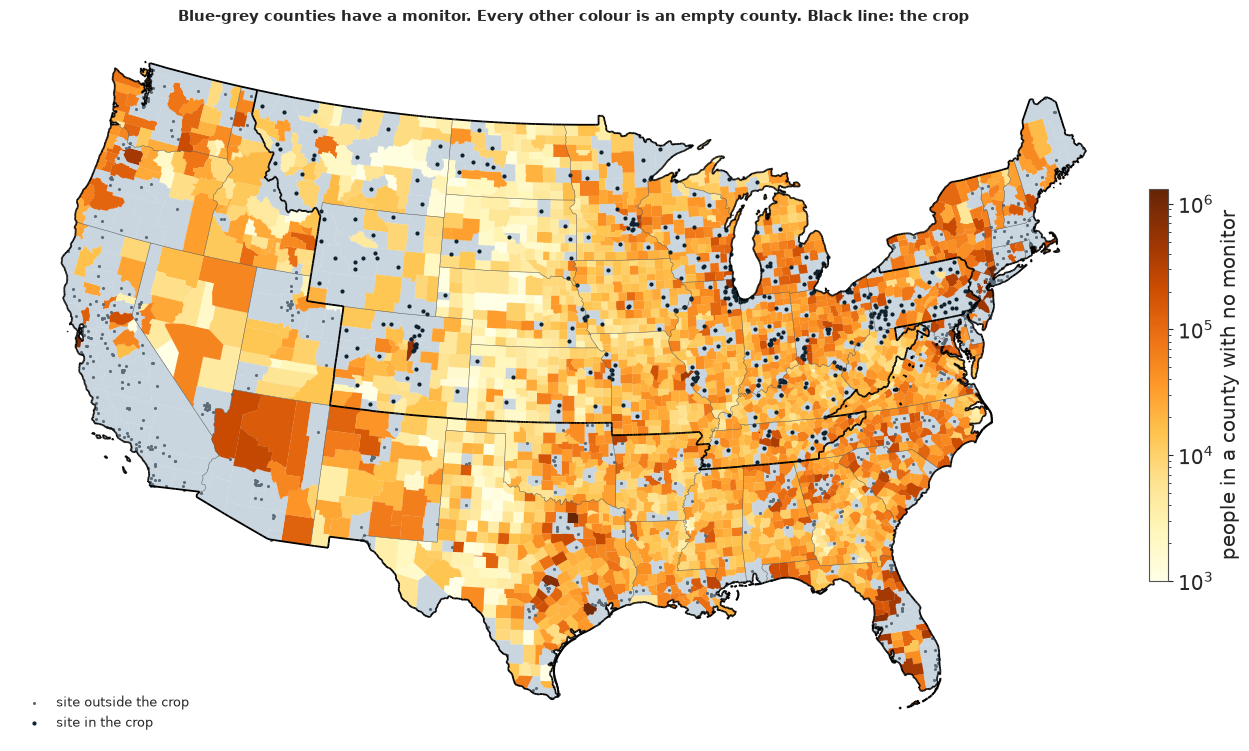

In [4]:
def albers(lon, lat, lon0=-96.0, lat0=37.5, p1=29.5, p2=45.5, radius=6371.0):
    """Albers equal-area conic in km, written out so that no GIS library is needed."""
    lon, lat, lon0, lat0, p1, p2 = map(np.radians, (lon, lat, lon0, lat0, p1, p2))
    n = (np.sin(p1) + np.sin(p2)) / 2
    c = np.cos(p1) ** 2 + 2 * n * np.sin(p1)
    rho = radius * np.sqrt(c - 2 * n * np.sin(lat)) / n
    rho0 = radius * np.sqrt(c - 2 * n * np.sin(lat0)) / n
    theta = n * (lon - lon0)
    return rho * np.sin(theta), rho0 - rho * np.cos(theta)


def county_shapes():
    """County outer rings in Albers km, with each ring's row in `counties`."""
    row = {fips: i for i, fips in enumerate(counties["fips"])}
    fixes = {"46113": "46102"}  # the geojson's Shannon County SD is now Oglala Lakota
    verts, owner = [], []
    for feature in json.loads(data.path("us_counties_geojson").read_text())["features"]:
        fips = fixes.get(feature["id"], feature["id"])
        if fips not in row:
            continue
        geometry = feature["geometry"]
        polygons = [geometry["coordinates"]] if geometry["type"] == "Polygon" else geometry["coordinates"]
        for polygon in polygons:
            ring = np.asarray(polygon[0], float)[:, :2]
            verts.append(np.column_stack(albers(ring[:, 0], ring[:, 1])))
            owner.append(row[fips])
    return verts, np.array(owner)


def outline(verts, owner, group):
    """Edges between two groups of counties, or with a county on one side only: no GIS dissolve."""
    seen = {}
    for ring, o in zip(verts, owner):
        rounded = np.round(ring, 3)
        for a, b in zip(map(tuple, rounded[:-1]), map(tuple, rounded[1:])):
            seen.setdefault((a, b) if a < b else (b, a), []).append(group[o])
    return np.array([edge for edge, groups in seen.items() if len(set(groups)) > 1 or len(groups) == 1])


VERTS, OWNER = county_shapes()
BORDERS = outline(VERTS, OWNER, counties["fips"].str[:2].to_numpy())
CROP_EDGE = outline(VERTS, OWNER, counties["small_crop"].to_numpy())
in_crop = counties["small_crop"].to_numpy()
crop_row = np.cumsum(in_crop) - 1  # county row to row of `table`
CROP_VERTS = [v for v, o in zip(VERTS, OWNER) if in_crop[o]]
CROP_OWNER = crop_row[OWNER[in_crop[OWNER]]]
points = np.concatenate(CROP_VERTS)
XLIM = (points[:, 0].min() - 25, points[:, 0].max() + 25)
YLIM = (points[:, 1].min() - 25, points[:, 1].max() + 25)
del points
near = [v for v, o in zip(VERTS, OWNER) if not in_crop[o] and v[:, 0].max() > XLIM[0]
        and v[:, 0].min() < XLIM[1] and v[:, 1].max() > YLIM[0] and v[:, 1].min() < YLIM[1]]
print(f"{len(VERTS):,} county polygons, {sum(map(len, VERTS)):,} vertices, {len(BORDERS):,} border edges")

STATE_CODE = {"Colorado": "CO", "Illinois": "IL", "Indiana": "IN", "Iowa": "IA", "Kansas": "KS",
              "Kentucky": "KY", "Michigan": "MI", "Minnesota": "MN", "Missouri": "MO", "Montana": "MT",
              "Nebraska": "NE", "North Dakota": "ND", "Ohio": "OH", "Pennsylvania": "PA",
              "South Dakota": "SD", "Tennessee": "TN", "West Virginia": "WV", "Wisconsin": "WI",
              "Wyoming": "WY"}
short_name = (table["county"].str.replace(" County", "").astype(object) + " "
              + table["state"].map(STATE_CODE).astype(object)).to_numpy(dtype=object)


def paint(ax, values, cmap, norm, labels=()):
    """The crop as a county map. Other counties stay pale, so that the crop's edge can be seen."""
    ax.add_collection(PolyCollection(near, facecolor="#f2f1ec", edgecolor="#ffffff", linewidth=0.2))
    palette = plt.get_cmap(cmap).with_extremes(bad="#e4e2db")
    shapes = PolyCollection(CROP_VERTS, array=np.asarray(values, float)[CROP_OWNER], cmap=palette, norm=norm,
                            edgecolor="face", linewidth=0.1)
    ax.add_collection(shapes)
    ax.add_collection(LineCollection(BORDERS, colors="#4a4a4a", linewidths=0.35))
    ax.set(xlim=XLIM, ylim=YLIM, aspect="equal")
    ax.axis("off")
    for i, text in labels:
        ax.annotate(text, (table["x_km"].iloc[i], table["y_km"].iloc[i]), xytext=(4, 4), fontsize=8,
                    textcoords="offset points", path_effects=[pe.withStroke(linewidth=2.2, foreground="w")])
    return shapes


fig, ax = plt.subplots(figsize=(12.5, 7.4), layout="constrained")
shade = np.where(counties["monitored"], np.nan, counties["population"].to_numpy(float))
everywhere = PolyCollection(VERTS, array=shade[OWNER], cmap=plt.get_cmap("YlOrBr").with_extremes(bad="#c9d6df"),
                            norm=LogNorm(1e3, 1.3e6), edgecolor="face", linewidth=0.1)
ax.add_collection(everywhere)
ax.add_collection(LineCollection(BORDERS, colors="#4a4a4a", linewidths=0.35))
ax.add_collection(LineCollection(CROP_EDGE, colors="k", linewidths=1.3))
outside = ~sites["small_crop"]
ax.scatter(sites.loc[outside, "x_km"], sites.loc[outside, "y_km"], s=5, c="#5b6b78", lw=0, label="site outside the crop")
ax.scatter(crop_sites["x_km"], crop_sites["y_km"], s=9, c="#10222e", lw=0, label="site in the crop")
ax.autoscale_view()
ax.set(aspect="equal")
ax.set_title("Blue-grey counties have a monitor. Every other colour is an empty county. Black line: the crop",
             fontsize=11)
ax.axis("off")
ax.legend(loc="lower left", fontsize=9)
fig.colorbar(everywhere, ax=ax, shrink=0.55, label="people in a county with no monitor", pad=0.01);

Four in five counties have no monitor, and they hold about 30% of the people. Empty does not always
mean small: the darkest counties have hundreds of thousands of residents.

The crop is the darker dots: the Midwest and Ohio Valley, where many sites sit close to the line,
with the Plains and Rockies, where counties are empty and clean. It holds both halves of the
lesson. It is not the whole country, and New Jersey is outside it, so a Pennsylvania pick near the
edge sees a truncated field.

### The first failure happened before any model ran

The daily file holds **two versions of the same instruments**. EPA's advisory of 26 August 2024
says to drop the original Teledyne T640 series, methods 236 and 238. They are 20.8% of the 2023
rows, under different POC numbers from the corrected series, and a first pass that kept them, or
took the maximum over POCs, gave a 2023 mean of 8.54 against 8.22 once clean. Each dot below is a
site in 2023, on the days both versions report.

            sites  site_days  original  corrected  above_only_in_original
pair                                                                     
236 vs 736    260      55784     10.74       9.57                      47
238 vs 738    133      27166      9.77       8.67                      13
Mean gap 1.14 µg/m³; 60 site-series change sides of 9.05


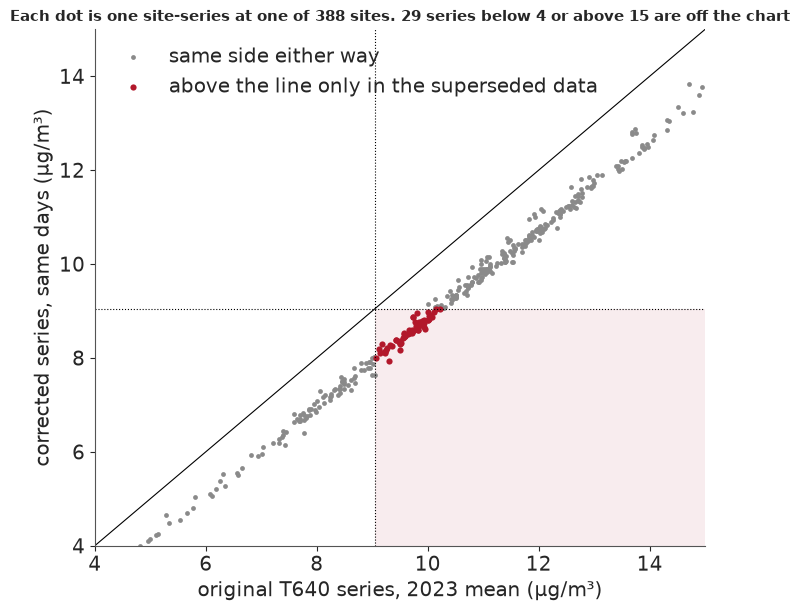

In [5]:
pairs = data.load("e89_t640_pairs")
pairs["flips"] = (pairs["original"] >= LINE) & (pairs["corrected"] < LINE)
print(pairs.groupby("pair").agg(sites=("site", "size"), site_days=("days", "sum"),
                                original=("original", "mean"), corrected=("corrected", "mean"),
                                above_only_in_original=("flips", "sum")).round(2).to_string())
print(f"Mean gap {(pairs['original'] - pairs['corrected']).mean():.2f} {UG}; "
      f"{pairs['flips'].sum()} site-series change sides of {LINE}")

low, high = 4.0, 15.0
fig, ax = plt.subplots(figsize=(6.8, 6), layout="constrained")
ax.axvspan(LINE, high, ymin=0, ymax=(LINE - low) / (high - low), color=ABOVE, alpha=0.08, lw=0)
ax.scatter(pairs.loc[~pairs["flips"], "original"], pairs.loc[~pairs["flips"], "corrected"], s=12,
           c=MUTED, lw=0, label="same side either way")
ax.scatter(pairs.loc[pairs["flips"], "original"], pairs.loc[pairs["flips"], "corrected"], s=20, c=ABOVE,
           lw=0, label="above the line only in the superseded data")
ax.plot([low, high], [low, high], color="k", lw=0.8)
ax.axvline(LINE, color="k", lw=0.8, ls=":")
ax.axhline(LINE, color="k", lw=0.8, ls=":")
ax.set(xlim=(low, high), ylim=(low, high), xlabel=f"original T640 series, 2023 mean ({UG})",
       ylabel=f"corrected series, same days ({UG})")
off_chart = ((pairs["original"] > high) | (pairs["original"] < low) | (pairs["corrected"] < low)).sum()
ax.set_title(f"Each dot is one site-series at one of {pairs['site'].nunique()} sites. {off_chart} series below 4 or "
             "above 15 are off the chart", fontsize=11)
ax.legend(loc="upper left");

The two versions exist side by side at 393 site-series, and the original reads 1.14 µg/m³ high on
average. That offset is about the size of the whole near-line margin: **60 site-series change sides of
9.05**, all of them in the shaded box. A model fitted to the raw file would learn a wrong map of exactly the
region this brief is about, and nothing in the fit would complain.

The fix cannot come from EPA's annual files: in 2023 their rows say "Multiple Methods Used" and
still hold the original data. So every annual value here is rebuilt from the daily files, as the
mean over surviving POCs and never the maximum. Is that close enough to EPA's own numbers? The
comparison below is against EPA's 2023-2025 design-value workbook.

In [6]:
epa = pd.DataFrame(checks["epa_comparison"]).T[
    ["sites", "median_abs", "p90_abs", "agree_9.05", "sites_dv_8_10", "agree_9.05_dv_8_10"]]
epa.index = ["No concurred events", "All valid sites", "Both FRM and T640 present"]
print(epa.astype(float).round(3).to_string())

                           sites  median_abs  p90_abs  agree_9.05  sites_dv_8_10  agree_9.05_dv_8_10
No concurred events        386.0       0.029    0.153       0.995           91.0               0.978
All valid sites            820.0       0.033    0.222       0.980          282.0               0.943
Both FRM and T640 present  231.0       0.076    0.446       0.957          121.0               0.917


Close: a median gap of 0.03 µg/m³. The honest column is the last one, sites with a design value
between 8 and 10, because far from the line agreement is easy. These means are **not** official
design values, and the tail sits at sites with both FRM and T640.

### Smoke stays in

A window mean hides its worst days. The ribbon below shows what share of US site-days passed 35
µg/m³, by day and latitude. Regulators can exclude concurred events; we do not, because the question
here is exposure, and smoke is exposure.

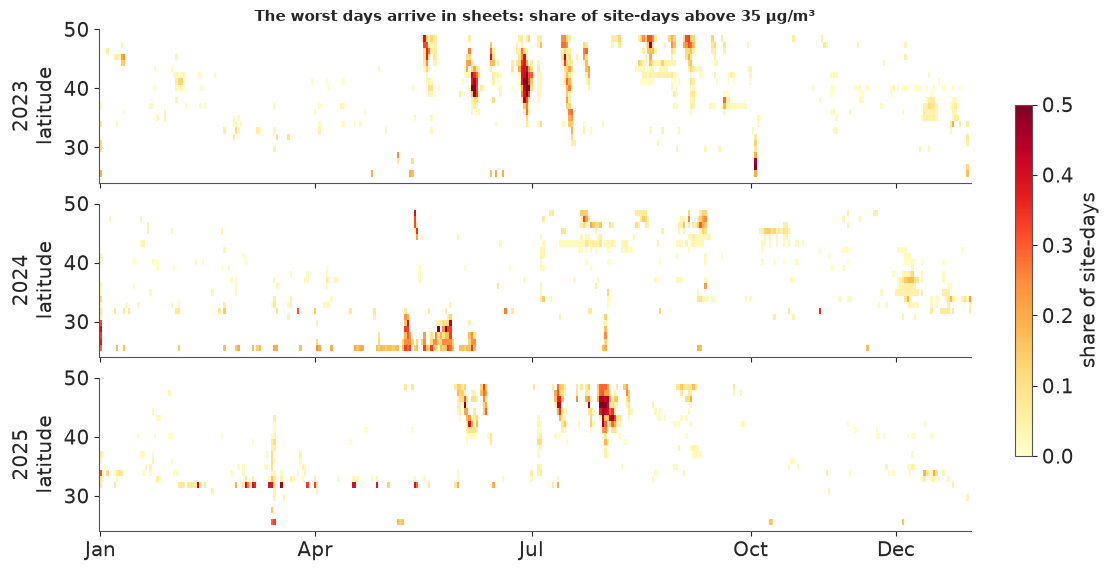

In [7]:
ribbon = data.load("e89_ribbon")
bands = [str(b) for b in range(25)]
edges = np.linspace(24, 50, 26)
fig, axes = plt.subplots(3, 1, figsize=(11, 5.6), sharex=True, layout="constrained")
for ax, (year, part) in zip(axes, ribbon.groupby("year")):
    grid = part.set_index("day")[bands].reindex(range(1, 367)).to_numpy(float).T
    mesh = ax.pcolormesh(np.arange(0.5, 367), edges, np.ma.masked_less_equal(np.nan_to_num(grid), 0),
                         cmap="YlOrRd", norm=Normalize(0, 0.5), rasterized=True)
    ax.set(ylabel=f"{year}\nlatitude", yticks=[30, 40, 50])
ax.set_xticks([1, 91, 182, 274, 335], ["Jan", "Apr", "Jul", "Oct", "Dec"])
axes[0].set_title("The worst days arrive in sheets: share of site-days above 35 " + UG, fontsize=11)
fig.colorbar(mesh, ax=axes, shrink=0.7, label="share of site-days");

Most of the year is empty, and then a sheet crosses many latitudes in days. 2023 has the most summer
sheets across 40-50 N, 2024 has fewer, and 2025 has a dense run from June to August. A site that missed
a year missed its sheets, which is why the model carries a term for which years a site has.

### A sparse schedule is measurement error, and we can size it

Many sites sample one day in three or six. We thinned near-daily sites to each schedule and compared
the annual mean with the full year, against the variance formula the data script uses. The formula
goes into the model as each site's known noise, `v`.

In [8]:
schedule = pd.DataFrame({(year, name): {"realised rms": row[f"1_in_{k}"]["rms"],
                                        "formula rms": row[f"1_in_{k}"]["formula_rms"]}
                         for year, row in checks["schedule_error"].items()
                         for k, name in ((3, "1-in-3"), (6, "1-in-6"), (12, "1-in-12"))})
print(schedule.round(2).to_string())

               2023                  2024                  2025               
             1-in-3 1-in-6 1-in-12 1-in-3 1-in-6 1-in-12 1-in-3 1-in-6 1-in-12
realised rms   0.31   0.65    1.12   0.26   0.47    0.71   0.26   0.50    0.84
formula rms    0.56   0.89    1.32   0.36   0.57    0.84   0.41   0.65    0.97


The formula's rms runs above the realised rms in all three years. That is not a wide margin at
the sparsest schedule: at 1-in-12 a site's error over its own formula sd has an rms of 0.99-1.16, so
there the formula is about right and no more. That bounds thinning error only. It is not evidence that a daily model would change nothing, because a daily model was not run.

## 2. The model, on a map

One row per site. Let $y_s$ be the log window mean and $v_s$ its known sampling variance:

$$y_s \sim \text{Normal}\big(\alpha + \beta_d\,\text{density}_s + w_s^\top\beta_m + a_s^\top\delta + f(s),\;
\tau_{\text{scale}(s)}^2 + v_s\big), \qquad f \sim \text{GP}\big(0,\ \eta^2\,\text{Matern}_{3/2}(\ell)\big).$$

In words: pollution is a smooth field over the map, plus a term for how crowded the county is, plus
corrections for which instrument and which years a site happens to have.

- **Density** is the one covariate that exists at empty counties as well as at monitors.
- **Method shares** $w_s$ put everything on an FRM footing: T640 and BAM do not read alike.
- **Year mix** $a_s$ is a sum-to-zero offset, because a site that missed 2023 missed the smoke.
- **One nugget per measurement scale.** A microscale site should not pretend to be a neighbourhood.
  This changes a site's spread only, not its mean. Section 3 shows where that falls short.
- **The field is integrated out**, so PyMC sees a 419 x 419 `MvNormal` and only 15 free parameters.
  Exact county conditionals come afterwards, one draw at a time.

Priors are LogNormal on the scales, centred on a 400 km lengthscale. What do they imply? We draw
whole fields at county centres in NumPy, because `pm.sample_prior_predictive` would only give us sites.

                      prior 5%  prior 95%  observed
sd of log site means      0.17       0.56      0.28
crop mean (µg/m³)         3.03      19.45      7.64


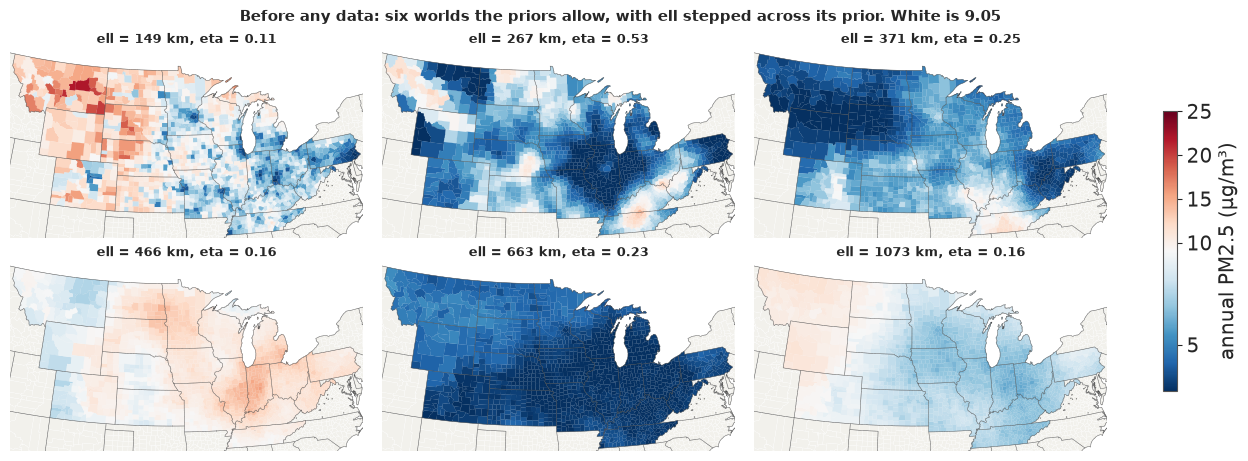

In [9]:
def design(frame, scale=None):
    """What the model needs per site. Density is standardised here unless a scale is given."""
    density = frame["log_density"].to_numpy(float)
    centre, spread = scale or (density.mean(), density.std())
    has = frame[[f"has_{y}" for y in YEARS]].to_numpy(float)
    xy = frame[["x_km", "y_km"]].to_numpy(float)
    return {"site": frame["site"].to_numpy(str), "y": frame["log_mean"].to_numpy(float),
            "v": frame["var_log"].to_numpy(float), "density": (density - centre) / spread,
            "density_scale": (centre, spread),
            "methods": frame[[f"share_{m}" for m in METHODS]].to_numpy(float),
            "years": has / has.sum(axis=1, keepdims=True), "xy": xy, "days": frame["days"].to_numpy(),
            "scale": frame["scale"].map(SCALES.index).to_numpy(int), "distance": distance(xy, xy)}


def distance(a, b):
    return np.sqrt(((a[:, None] - b[None]) ** 2).sum(axis=-1))


def matern32(gap, ell):
    r = np.sqrt(3.0) * gap / ell
    return (1 + r) * np.exp(-r)


def m1(d, method_prior=(0.0, 0.2)):
    """The field integrated out: a marginal GP with 15 free parameters."""
    coords = {"method": METHODS, "year": YEARS, "scale": SCALES, "site": d["site"]}
    with pm.Model(coords=coords) as model:
        alpha = pm.Normal("alpha", 2.0, 0.5)
        beta_density = pm.Normal("beta_density", 0.0, 0.2)
        beta_method = pm.Normal("beta_method", *method_prior, dims="method")
        delta = pm.ZeroSumNormal("delta", sigma=0.1, dims="year")
        mu = (alpha + beta_density * d["density"] + pm.math.dot(d["methods"], beta_method)
              + pm.math.dot(d["years"], delta))
        eta = pm.LogNormal("eta", *PRIOR_ETA)
        ell = pm.LogNormal("ell", *PRIOR_ELL)
        tau = pm.LogNormal("tau", *PRIOR_TAU, dims="scale")
        r = np.sqrt(3.0) * pt.constant(d["distance"]) / ell
        cov = eta ** 2 * (1 + r) * pt.exp(-r) + pt.diag(tau[d["scale"]] ** 2 + d["v"])
        pm.MvNormal("y", mu=mu, cov=cov, observed=d["y"], dims="site")
    return model


d = design(crop_sites)
xy_county = table[["x_km", "y_km"]].to_numpy(float)
gap_county = distance(xy_county, xy_county)
density_county = (table["log_density"].to_numpy(float) - d["density_scale"][0]) / d["density_scale"][1]

with stage("prior check"):
    prior_rng = np.random.default_rng(RANDOM_SEED)
    rows = []
    for _ in range(200):
        eta, ell = prior_rng.lognormal(*PRIOR_ETA), prior_rng.lognormal(*PRIOR_ELL)
        tau = prior_rng.lognormal(*PRIOR_TAU, size=len(SCALES))
        mean = (prior_rng.normal(2.0, 0.5) + prior_rng.normal(0, 0.2) * d["density"]
                + d["methods"] @ prior_rng.normal(0, 0.2, size=3))
        cov = eta ** 2 * matern32(d["distance"], ell) + np.diag(tau[d["scale"]] ** 2 + d["v"])
        rows.append(prior_rng.multivariate_normal(mean, cov, method="cholesky"))
    prior_y = np.array(rows)
    print(pd.DataFrame({"prior 5%": [np.quantile(prior_y.std(axis=1), 0.05),
                                     np.quantile(np.exp(prior_y).mean(axis=1), 0.05)],
                        "prior 95%": [np.quantile(prior_y.std(axis=1), 0.95),
                                      np.quantile(np.exp(prior_y).mean(axis=1), 0.95)],
                        "observed": [d["y"].std(), np.exp(d["y"]).mean()]},
                       index=["sd of log site means", f"crop mean ({UG})"]).round(2).to_string())

    fig, axes = plt.subplots(2, 3, figsize=(12.5, 4.5), layout="constrained")
    for ax, q in zip(axes.flat, (0.05, 0.25, 0.45, 0.6, 0.8, 0.95)):  # ell across its prior, short to long
        ell = np.exp(PRIOR_ELL[0] + PRIOR_ELL[1] * ndtri(q))
        eta = prior_rng.lognormal(*PRIOR_ETA)
        lower = linalg.cholesky(eta ** 2 * matern32(gap_county, ell) + 1e-6 * np.eye(len(table)), lower=True)
        world = (prior_rng.normal(2.0, 0.5) + prior_rng.normal(0, 0.2) * density_county
                 + lower @ prior_rng.normal(size=len(table)))
        shapes = paint(ax, np.exp(world), "RdBu_r", TwoSlopeNorm(LINE, 3.0, 25.0))
        ax.set_title(f"ell = {ell:.0f} km, eta = {eta:.2f}", fontsize=9)
    fig.colorbar(shapes, ax=axes, shrink=0.7, label=f"annual PM2.5 ({UG})")
    fig.suptitle("Before any data: six worlds the priors allow, with ell stepped across its prior. "
                 "White is 9.05", fontsize=11)
    del lower, world, prior_y
    gc.collect();

The priors are wide but not silly. They cover the observed spread of sites and the observed crop mean, and
the fields run from patchy at short `ell` to one regional tone at long `ell`. The maps also show the
density term: crowded counties stand out from their neighbours.

Now the fit: nutpie through `pm.sample`, four chains, **400 tuning steps and 500 draws**, one BLAS
thread per chain. That is fewer draws than the usual 1,000: we only need 200 evenly spaced draws
for value of information, and this model mixes well.

In [10]:
NAMES = ("alpha", "beta_density", "beta_method", "delta", "eta", "ell", "tau")


def fit_m1(design_table, seed, **options):
    with m1(design_table, **options):
        return pm.sample(draws=500, tune=400, chains=4, cores=CHAINS_AT_ONCE, random_seed=seed,
                         progressbar=False, compute_convergence_checks=False)


def draws_of(idata):
    """Parameters as plain arrays, (chain, draw, ...): all that the rest of the notebook needs."""
    return {name: idata.posterior[name].to_numpy() for name in NAMES}


with stage("fit M1"):
    idata = fit_m1(d, RANDOM_SEED)
summary = az.summary(idata, var_names=list(NAMES), ci_prob=0.9, ci_kind="eti", round_to=3)
print(summary.to_string())
print(f"max r_hat {summary['r_hat'].astype(float).max():.3f}; "
      f"min bulk ESS {summary['ess_bulk'].astype(float).min():.0f}; "
      f"min tail ESS {summary['ess_tail'].astype(float).min():.0f}; "
      f"divergences {int(idata.sample_stats['diverging'].sum())}; "
      f"tuning steps {idata.posterior.attrs.get('tuning_steps', 'not recorded')}; "
      f"mean leapfrogs {idata.sample_stats['n_steps'].mean().item():.1f}")
fit = draws_of(idata)

                        mean      sd  eti90_lb  eti90_ub  ess_bulk  ess_tail  r_hat  mcse_mean  mcse_sd
alpha                  1.961   0.080     1.830     2.089  2223.855  1431.681  1.004      0.002    0.002
beta_density           0.087   0.013     0.066     0.108  3500.384  1621.625  1.005      0.000    0.000
beta_method[T640]      0.033   0.029    -0.015     0.080  1894.970  1652.656  1.002      0.001    0.001
beta_method[BAM]      -0.111   0.035    -0.168    -0.055  1982.255  1572.491  1.001      0.001    0.001
beta_method[other]     0.007   0.043    -0.066     0.077  2177.948  1566.117  1.003      0.001    0.001
delta[2023]            0.112   0.029     0.064     0.159  3384.639  1910.844  1.001      0.001    0.001
delta[2024]           -0.067   0.039    -0.131    -0.002  3825.586  1740.197  1.000      0.001    0.001
delta[2025]           -0.045   0.029    -0.095     0.005  4017.460  1662.501  0.999      0.000    0.001
eta                    0.243   0.040     0.190     0.320  1826.1

A clean fit: no divergences after warm-up, r_hat at most about 1.01, and a smallest ESS above 1,000, in
about 2.5 minutes on 2 cores. A few parameters deserve a plain reading.

- `ell` is about 310 km (90% interval 209-472), well inside its prior, so the data did set it.
- Each sd of log density adds about 9% to PM2.5. Crowded counties read higher.
- BAM reads about 10% below FRM. T640 is +3%, and its interval spans zero. Instruments compared side
  by side say about -3% and +6%. This term is learned across sites, and BAM sites are rural, so it
  can pick up rural air. Predictions rest on it, so section 8 refits with the pairs.
- 2023 ran about 12% above the window's average year.
- The site nugget `tau` is 10-17%. **Remember it.** It says a monitor's reading differs from the
  smooth regional field by about that much, and it matters again in section 4.

The number that matters most is `ell`, because it says how far one monitor can see. Here it is as
correlation against distance, before and after the data.

{'100 km': 0.88, '200 km': 0.67, '400 km': 0.32}


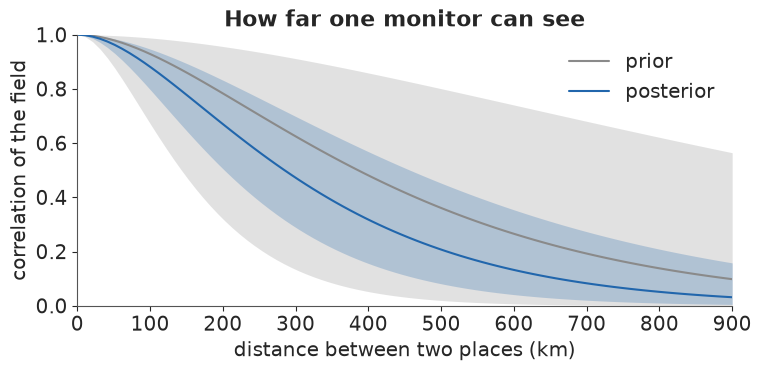

In [11]:
km = np.linspace(1, 900, 90)
prior_ell = np.random.default_rng(RANDOM_SEED).lognormal(*PRIOR_ELL, size=2000)
post_ell = fit["ell"].ravel()
fig, ax = plt.subplots(figsize=(7.5, 3.6), layout="constrained")
for sample, colour, label in ((prior_ell, MUTED, "prior"), (post_ell, BELOW, "posterior")):
    bands_ = matern32(km[:, None], sample[None])
    low, mid, high = np.quantile(bands_, [0.05, 0.5, 0.95], axis=1)
    ax.fill_between(km, low, high, color=colour, alpha=0.25, lw=0)
    ax.plot(km, mid, color=colour, label=label)
ax.set(xlabel="distance between two places (km)", ylabel="correlation of the field",
       title="How far one monitor can see", ylim=(0, 1), xlim=(0, 900))
ax.legend();
reach = {k: float(np.median(matern32(k, post_ell))) for k in (100, 200, 400)}
print({f"{k} km": round(v, 2) for k, v in reach.items()})

## 3. Can the map see what it has not measured?

In a GP, checks that reuse the fitted field are in-sample. So we use three checks that do not. The
replicated networks use 200 posterior draws. The two hold-outs use the median hyperparameters and the
inverse of the site covariance (`az.loo` would see one observation from an `MvNormal`).

- **Replicated data:** draw a new field, a new network reading and ask whether the spread and the
  number of near-line sites look like ours.
- **Hold out one site**, or a whole **200 km block**, which is closer to what an empty county faces.
- **Hold out the new sites**, those first seen in 2023 or later, and predict them from older sites.
  The one honest leak: the hyperparameters saw these sites.

                        replicated 5%  replicated 95%  observed
sd of log means                 0.214           0.355     0.276
share of sites in 8-10          0.095           0.325     0.422
largest log mean                2.444           3.020     2.467
                      sites   bias  se of bias   rmse  mean predictive sd  90% coverage
one site              419.0 -0.001       0.007  0.142               0.135         0.909
200 km block          419.0  0.011       0.008  0.156               0.151         0.919
new sites              34.0 -0.027       0.027  0.162               0.147         0.882
new sites over 25 km   18.0 -0.096       0.039  0.192               0.163         0.889
New sites over 25 km with a window mean of 8-10: 3
                sites  mean held-out error     se
scale                                            
MICROSCALE         16                0.026  0.038
MIDDLE SCALE       23                0.059  0.019
NEIGHBORHOOD      243               -0.005  0.009
REG

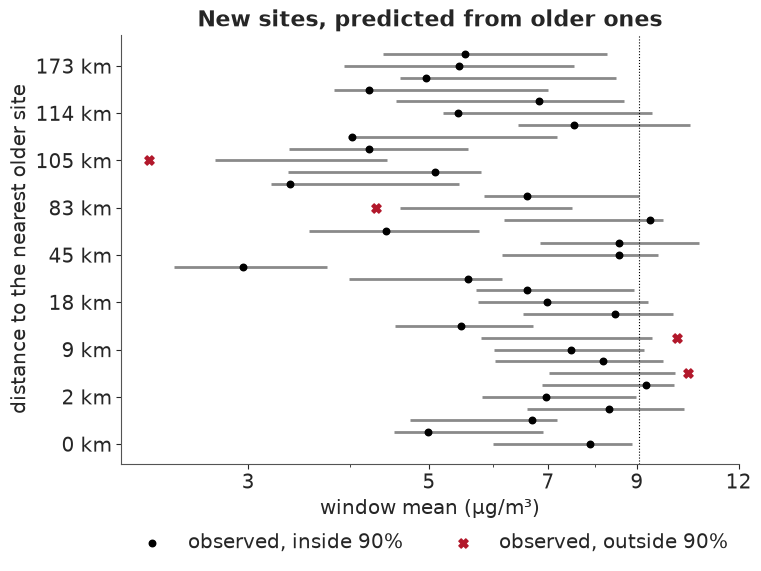

In [12]:
def site_mean(design_table, draw):
    return (draw["alpha"] + draw["beta_density"] * design_table["density"]
            + design_table["methods"] @ draw["beta_method"] + design_table["years"] @ draw["delta"])


def median_draw(chains):
    return {k: np.median(v.reshape(-1, *v.shape[2:]), axis=0) for k, v in chains.items()}


def site_covariance(design_table, draw):
    return (draw["eta"] ** 2 * matern32(design_table["distance"], draw["ell"])
            + np.diag(draw["tau"][design_table["scale"]] ** 2 + design_table["v"]))


def hold_out(precision_matrix, residual, groups):
    """Leave each group out, from the precision matrix: errors and sds of the held-out sites."""
    error, sd = np.empty_like(residual), np.empty_like(residual)
    scaled = precision_matrix @ residual
    for group in groups:
        cov = np.linalg.inv(precision_matrix[np.ix_(group, group)])
        error[group] = cov @ scaled[group]
        sd[group] = np.sqrt(np.diag(cov))
    return error, sd


def scorecard(error, sd):
    return {"sites": error.size, "bias": error.mean(), "se of bias": error.std() / np.sqrt(error.size),
            "rmse": np.sqrt((error ** 2).mean()), "mean predictive sd": sd.mean(),
            "90% coverage": (np.abs(error / sd) < 1.645).mean()}


with stage("checks"):
    best = median_draw(fit)
    residual = d["y"] - site_mean(d, best)
    precision_sites = np.linalg.inv(site_covariance(d, best))
    n_sites = len(residual)

    # replicated networks, one per posterior draw
    stacked = {k: v.reshape(-1, *v.shape[2:]) for k, v in fit.items()}
    check_rng = np.random.default_rng(RANDOM_SEED)
    stats = []
    for i in check_rng.choice(stacked["ell"].size, 200, replace=False):
        draw = {k: v[i] for k, v in stacked.items()}
        replica = check_rng.multivariate_normal(site_mean(d, draw), site_covariance(d, draw),
                                                method="cholesky")
        stats.append((replica.std(), ((replica > np.log(8)) & (replica < np.log(10))).mean(), replica.max()))
    stats = np.array(stats)
    observed = (d["y"].std(), ((d["y"] > np.log(8)) & (d["y"] < np.log(10))).mean(), d["y"].max())
    print(pd.DataFrame(np.c_[np.quantile(stats, [0.05, 0.95], axis=0).T, observed],
                       columns=["replicated 5%", "replicated 95%", "observed"],
                       index=["sd of log means", "share of sites in 8-10", "largest log mean"]).round(3).to_string())

    # one site, 200 km blocks, and the new sites
    cells = pd.factorize(pd.Series(zip((d["xy"][:, 0] // 200).astype(int), (d["xy"][:, 1] // 200).astype(int))))[0]
    is_new = crop_sites["first_year"].to_numpy() >= 2023
    old_near = distance(d["xy"][is_new], d["xy"][~is_new]).min(axis=1)
    new_groups = [np.flatnonzero(is_new)]
    new_error, new_sd = hold_out(precision_sites, residual, new_groups)
    one_error, one_sd = hold_out(precision_sites, residual, [[i] for i in range(n_sites)])
    block_error, block_sd = hold_out(precision_sites, residual, [np.flatnonzero(cells == c) for c in np.unique(cells)])
    far = old_near > 25
    print(pd.DataFrame({"one site": scorecard(one_error, one_sd),
                        "200 km block": scorecard(block_error, block_sd),
                        "new sites": scorecard(new_error[is_new], new_sd[is_new]),
                        "new sites over 25 km": scorecard(new_error[is_new][far], new_sd[is_new][far])}
                       ).T.round(3).to_string())
    near_line = (np.exp(d["y"][is_new]) > 8) & (np.exp(d["y"][is_new]) < 10)
    print(f"New sites over 25 km with a window mean of 8-10: {(far & near_line).sum()}")
    by_scale = pd.DataFrame({"scale": crop_sites["scale"], "error": one_error}).groupby("scale")["error"]
    print(pd.DataFrame({"sites": by_scale.size(), "mean held-out error": by_scale.mean(),
                        "se": by_scale.std() / np.sqrt(by_scale.size())}).round(3).to_string())

    order = np.argsort(old_near)
    fig, ax = plt.subplots(figsize=(7.5, 5.6), layout="constrained")
    centre = (d["y"] - new_error)[is_new][order]
    half = 1.645 * new_sd[is_new][order]
    seen = d["y"][is_new][order]
    missed = np.abs(seen - centre) > half
    rows = np.arange(is_new.sum())
    ax.hlines(rows, np.exp(centre - half), np.exp(centre + half), color=MUTED, lw=2)
    ax.scatter(np.exp(seen)[~missed], rows[~missed], s=22, c="k", zorder=3, label="observed, inside 90%")
    ax.scatter(np.exp(seen)[missed], rows[missed], s=44, c=ABOVE, marker="X", zorder=3, label="observed, outside 90%")
    ax.axvline(LINE, color="k", lw=0.8, ls=":")
    ax.set_yticks(rows[::4], [f"{km_:.0f} km" for km_ in old_near[order][::4]])
    ax.set(xscale="log", xlabel=f"window mean ({UG})", ylabel="distance to the nearest older site",
           title="New sites, predicted from older ones")
    ax.set_xticks([3, 5, 7, 9, 12], ["3", "5", "7", "9", "12"])
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False);

**One check fails, and we leave it open.** Replicated networks match the spread and the extreme, but
42% of real sites sit between 8 and 10, against 10-33% of replicated sites. Real sites pile up near the
line more than a smooth Gaussian field can. Perhaps that is where monitors get placed, or perhaps
the log-normal shape is wrong. So do not over-read the fine detail near the line.

**Held-out sites behave.** Leaving out one site or a whole 200 km block, the error is about 15% with
90% intervals covering 91-92%. Block error is only a little larger, as it should be with `ell` near 310 km.

**The new sites are the warning.** 34 sites in the crop first reported in 2023 or later, and the
model predicts them from older sites with almost no bias overall. But the 18 more than 25 km from
any older site read about 9% **below** prediction (se 4%), and you can see the dots lean left at the
top of the figure. That is what an upward-biased network would produce: if monitors sit where the
air is worse, the model reads high in the gaps. It is also what rural sites near urban ones would
produce. This is a rough look. Only 3 of those 18 sites are near the line, so **it cannot validate
wrong-call rates**, and M2, the model built to test this, was not sampled. We carry it as a named
risk: the map may run high in empty places.

**Middle-scale sites read high.** The last table holds out one site at a time, by measurement scale.
Middle-scale sites sit about 6% above prediction (se 2%, 23 sites), and the other scales are within
noise. These sites sit near sources, and the model gives scale a variance and no mean, so they may pull
the field up in the near-line cities where they stand. We leave that in and name it: a mean term for
scale, or treating these sites as source-oriented, is not tested here.

## 4. Which calls are close?

For each posterior draw of the hyperparameters, the county field is exactly Gaussian. We take 200
draws evenly spaced through the chains. Hyperparameters stay integrated over: the final probability
is a mixture over draws, not a plug-in at the median.

The covariance of 1,535 counties would cost 1.9 GB over 200 draws. It has a simple form, though:
$S = K_{cc} - H^\top H$, the prior covariance less what the 419 sites explain, where
$H = L^{-1} K_{sc}$ is 419 x 1,535. The prior part is a formula, so we store only $H$: 0.5 GB, and a
row of $S$ when we need it. Our first draft stored $S$ and was killed at the 3 GB cap.

Expected wrong calls now: 10.43 million people of 103.9 million (modelled, not observed)
Undecided counties (p between 0.01 and 0.99): 452 of 1535 (29%)
Counties called above 9.0: 9, holding 10.9 million people
Share of those wrong-call people in counties that already have a site: 89%
Sites against calls: 32 counties have a site at or above 9.05, and the model calls 7 of them above; 12 have every site above it, and 3 of those are called above
                                                 people at risk (M)  of which monitored (M)  undecided counties
a site settles its county (sampling noise only)                1.37                    0.23                 347
this notebook: truth is the smooth field                      10.43                    9.28                 452
the nugget is real air at the county centre                   22.88                   17.96                1272
                    people  P(above)  monitored  people at risk of a wrong call
Cook IL          5182620.

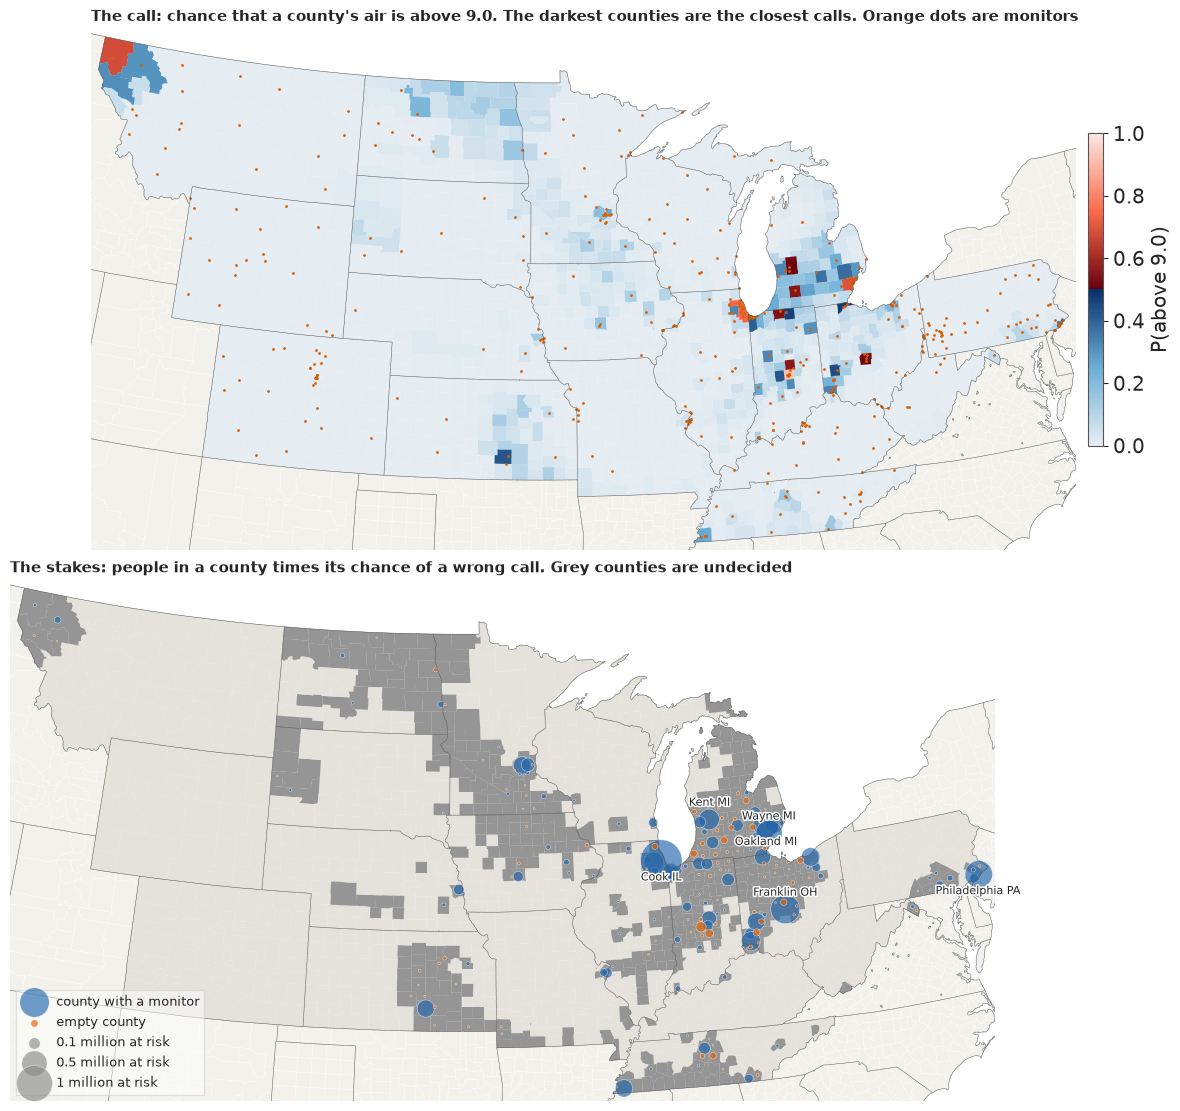

In [13]:
def thin(chains, count, shift=0):
    """`count` draws evenly spaced through the chains; `shift` moves to a disjoint set."""
    total = chains["ell"].shape[0] * chains["ell"].shape[1]
    take = (np.linspace(0, total - 1, count).round().astype(int) + shift) % total
    return {k: v.reshape(total, *v.shape[2:])[take] for k, v in chains.items()}


def conditional(design_table, draw):
    """Exact mean of the latent field at the county centres, and H, for one draw."""
    lower = linalg.cholesky(site_covariance(design_table, draw), lower=True, check_finite=False)
    cross = draw["eta"] ** 2 * matern32(distance(xy_county, design_table["xy"]), draw["ell"])
    half = linalg.solve_triangular(lower, cross.T, lower=True, check_finite=False)
    residuals = linalg.solve_triangular(lower, design_table["y"] - site_mean(design_table, draw),
                                        lower=True, check_finite=False)
    density = (table["log_density"].to_numpy(float) - design_table["density_scale"][0]) / design_table["density_scale"][1]
    return draw["alpha"] + draw["beta_density"] * density + half.T @ residuals, half  # FRM, whole window


def make_field(design_table, chains, count=200, shift=0):
    """County means, H, and the noise of a new monitor, for `count` draws, as float32."""
    draws = thin(chains, count, shift)
    means = np.empty((count, len(table)), np.float32)
    half = np.empty((count, len(design_table["y"]), len(table)), np.float32)

    def fill(i):
        means[i], half[i] = conditional(design_table, {k: v[i] for k, v in draws.items()})

    with ThreadPoolExecutor(WORKERS) as pool:
        list(pool.map(fill, range(count)))
    noise = draws["tau"][:, SCALES.index("NEIGHBORHOOD")] ** 2 + np.median(design_table["v"][design_table["days"] >= 900])
    return {"means": means, "half": half, "noise": noise, "eta2": np.float32(draws["eta"] ** 2),
            "ells": np.float32(draws["ell"]), "ell": float(np.median(chains["ell"]))}


def covariance_rows(field_, rows_, keep=slice(None)):
    """Rows of S against every county: (draws, len(rows_), counties)."""
    eta2, ells = field_["eta2"][keep][:, None, None], field_["ells"][keep][:, None, None]
    half = field_["half"][keep]
    return eta2 * matern32(gap32[rows_], ells) - half[:, :, rows_].transpose(0, 2, 1) @ half


del idata
gc.collect()
with stage("county conditionals"):
    field = make_field(d, fit)
gap32 = np.float32(gap_county)
variance = field["eta2"][:, None] - (field["half"] ** 2).sum(axis=1)
p_now = ndtr((field["means"] - np.log(LINE)) / np.sqrt(variance)).mean(axis=0)
risk = population * np.minimum(p_now, 1 - p_now)
mean_log = field["means"].mean(axis=0)
sd_log = np.sqrt(variance.mean(axis=0) + field["means"].var(axis=0))
sd_ug = np.exp(mean_log) * sd_log
undecided = (p_now > 0.01) & (p_now < 0.99)
print(f"Expected wrong calls now: {risk.sum() / 1e6:.2f} million people of {population.sum() / 1e6:.1f} million "
      f"(modelled, not observed)")
print(f"Undecided counties (p between 0.01 and 0.99): {undecided.sum()} of {len(table)} ({undecided.mean():.0%})")
print(f"Counties called above 9.0: {(p_now > 0.5).sum()}, holding {population[p_now > 0.5].sum() / 1e6:.1f} million people")
monitored = table["monitored"].to_numpy()
print(f"Share of those wrong-call people in counties that already have a site: {risk[monitored].sum() / risk.sum():.0%}")

readings = pd.DataFrame({"fips": crop_sites["fips"], "reading": np.exp(d["y"]),
                         "settled": ndtr((d["y"] - np.log(LINE)) / np.sqrt(np.maximum(d["v"], 1e-8)))})
readings = readings.groupby("fips").agg(top=("reading", "max"), low=("reading", "min"), settled=("settled", "max"))
readings = table[["fips"]].join(readings, on="fips")
top_site, low_site = readings["top"].to_numpy(), readings["low"].to_numpy()
p_settled = np.where(monitored, readings["settled"].to_numpy(), p_now)
nugget_real = field["noise"][:, None] - np.median(d["v"][d["days"] >= 900])  # tau^2 of a neighbourhood site
p_local = ndtr((field["means"] - np.log(LINE)) / np.sqrt(variance + nugget_real)).mean(axis=0)
called = p_now > 0.5
print(f"Sites against calls: {(top_site >= LINE).sum()} counties have a site at or above {LINE}, and the model calls "
      f"{(called & (top_site >= LINE)).sum()} of them above; {(low_site >= LINE).sum()} have every site above it, and "
      f"{(called & (low_site >= LINE)).sum()} of those are called above")
conventions = pd.DataFrame({
    "people at risk (M)": [(population * np.minimum(p, 1 - p)).sum() / 1e6 for p in (p_settled, p_now, p_local)],
    "of which monitored (M)": [(population * np.minimum(p, 1 - p))[monitored].sum() / 1e6 for p in (p_settled, p_now, p_local)],
    "undecided counties": [((p > 0.01) & (p < 0.99)).sum() for p in (p_settled, p_now, p_local)]},
    index=["a site settles its county (sampling noise only)", "this notebook: truth is the smooth field",
           "the nugget is real air at the county centre"])
print(conventions.round(2).to_string())
worst = np.argsort(-risk)[:8]
print(pd.DataFrame({"people": population[worst].round(), "P(above)": p_now[worst].round(2),
                    "monitored": table["monitored"].to_numpy()[worst],
                    "people at risk of a wrong call": risk[worst].round()},
                   index=short_name[worst]).to_string())
allegheny = int(np.flatnonzero(short_name == "Allegheny PA")[0])
print(f"Allegheny PA: P(above) {p_now[allegheny]:.3f}, top site {top_site[allegheny]:.2f} {UG}, "
      f"{population[allegheny] / 1e6:.2f} million people")

fig, axes = plt.subplots(2, 1, figsize=(12.5, 11), layout="constrained")
shapes = paint(axes[0], p_now, CLOSE_CALL, Normalize(0, 1))
axes[0].scatter(crop_sites["x_km"], crop_sites["y_km"], s=4, c="#d95f02", lw=0)
axes[0].set_title("The call: chance that a county's air is above 9.0. The darkest counties are the closest "
                  "calls. Orange dots are monitors", loc="left", fontsize=11)
fig.colorbar(shapes, ax=axes[0], shrink=0.6, label="P(above 9.0)", pad=0.01)
paint(axes[1], np.where(undecided, 0.5, np.nan), "Greys", Normalize(0, 1))
for mask, colour, label in ((monitored, BELOW, "county with a monitor"), (~monitored, PICK, "empty county")):
    show = mask & (risk > 2e3)
    axes[1].scatter(xy_county[show, 0], xy_county[show, 1], s=risk[show] / 1.5e3, facecolor=colour, alpha=0.65,
                    edgecolor="w", lw=0.4, label=label)
for rank_, i in enumerate(np.argsort(-risk)[:6]):
    axes[1].annotate(short_name[i], xy_county[i], xytext=(0, 12 if rank_ % 2 else -12), textcoords="offset points",
                     fontsize=8, ha="center", va="center", path_effects=[pe.withStroke(linewidth=2.2, foreground="w")])
for size in (1e5, 5e5, 1e6):
    axes[1].scatter([], [], s=size / 1.5e3, facecolor=MUTED, alpha=0.65, edgecolor="w", lw=0.4,
                    label=f"{size / 1e6:g} million at risk")
axes[1].legend(loc="lower left", frameon=True, fontsize=9)
axes[1].set_title("The stakes: people in a county times its chance of a wrong call. "
                  "Grey counties are undecided", loc="left", fontsize=11);

The top map shows how few calls are close. Most of the crop is pale: clearly below the line. Only 9
or so counties are called above it, but they hold about 11 million people. Across the builds, about
**10-11 million people** of 103.9 million are expected to be on the wrong side of the line (modelled,
not observed), and about 30% of counties are undecided.

The bottom map is the surprise. **About nine in ten of those people live in counties that already
have a monitor**: the blue circles. Franklin County OH has four monitors, all reading about 9.05-9.86, and
still sits near P = 0.5. Allegheny PA has a site at 10.25 and 1.2 million people, and P is about 0.
That is the nugget from section 2. A site's reading is not the county's field, so the model does
not treat a monitor as settling its own county. A planner will spot this at once: about 32 counties
have a site at or above the line, and the model calls about 7 of them above. Of the 12 where every
site is above, it calls about 3.

This is a modelling choice with a large effect, and it does not describe law: legally, Franklin's
call comes from its monitors. **The table above sizes it.** Let a monitored county be settled by its
highest site, and about 1.4 million are at risk. Treat the nugget as real air at every county centre,
and about 23 million are, in about 1,270 undecided counties. That last case is an upper one, since
some of the nugget is instrument difference. Our 10 million sits between them, and it is a statement
about the smooth field, not about what any one person breathes. The balance moves as well: about four
in five of those at risk are in monitored counties in the upper case, but under one in five if a site
settles its county, when about 1.1 of the 1.4 million are in empty counties. Hold on to this, because
it decides what the shortlist means.

## 5. Uncertainty is not value

The obvious rule is to put monitors where we are most uncertain. The better question is the one
from the top: **what would we do differently if we knew?**

For one candidate $c$ and one draw, a new reading $y$ has predictive variance $S_{cc} + n$ and moves
every county's mean by a rank-one update. So, in closed form, with no simulation of the field:

1. Take 16 equal-probability readings from the predictive mixture over draws.
2. For each reading, reweight the draws by how well they predicted it, update each county, and
   average over draws to get the county's new $P(\text{above})$.
3. Expected loss is the average over readings of people times $\min(p, 1 - p)$.

The fall in that loss is the **expected value of sample information** (EVSI) of the site. To save
time we count only counties within $3\ell$ and still undecided.

Two tricks keep this cheap. A score only reads the covariance of a candidate with undecided
counties, so that block is built once. And later rounds need the covariance after earlier picks: the
pilot overwrote it in place, which spent a whole covariance per run. Here a pick stores only its
low-rank factor, 25 MB for 20 picks, so one field serves every run below, and subsets of draws are
views with no copy.

In [14]:
def reading_nodes(mean, variance_, nodes):
    """Midpoints of `nodes` equal-probability bins of the mixture predictive of the reading."""
    sd = np.sqrt(variance_)
    grid = np.linspace((mean - 6 * sd).min(), (mean + 6 * sd).max(), 256)
    cdf = ndtr((grid[:, None] - mean) / sd).mean(axis=1)
    return np.interp((np.arange(nodes) + 0.5) / nodes, cdf, grid)


def update_weights(y, mean, variance_):
    """Each draw's posterior weight after reading `y` (axes: readings, draws)."""
    log = -0.5 * (y[:, None] - mean) ** 2 / variance_ - 0.5 * np.log(variance_)
    return np.exp(log - logsumexp(log, axis=1, keepdims=True))


def probability_above(y, weights, mu, var, cross, mu_c, q, line):
    """P(above the line) per county after each reading: rank-one update in each draw, then mix."""
    gain = cross / q[:, None]
    shift = (y[:, None] - mu_c)[:, :, None]
    sd = np.sqrt(np.maximum(var - gain * cross, 1e-10))
    return (weights[:, :, None] * ndtr((mu + shift * gain - line) / sd)).sum(axis=1)


def loss(p, weight, objective):
    """Expected loss, calling each county at p = 0.5."""
    if objective == "missed":  # called below, truly above
        return (weight * np.where(p < 0.5, p, 0.0)).sum(axis=-1)
    if objective == "false":   # called above, truly below
        return (weight * np.where(p >= 0.5, 1 - p, 0.0)).sum(axis=-1)
    return (weight * np.minimum(p, 1 - p)).sum(axis=-1)


def open_block(field_, line):
    """Covariance of every candidate with the undecided counties: all a score ever reads."""
    key = f"block_{line}"
    if key not in field_:
        variance_ = field_["eta2"][:, None] - (field_["half"] ** 2).sum(axis=1)
        p = ndtr((field_["means"] - np.float32(np.log(line))) / np.sqrt(variance_)).mean(axis=0)
        where = np.flatnonzero((p > 0.005) & (p < 0.995))  # a wider net than `open`, for subsets of draws
        block = np.empty((len(variance_), len(candidates), where.size), np.float32)
        gaps = gap32[np.ix_(candidates, where)]

        def fill(i):
            half = field_["half"][i]
            block[i] = field_["eta2"][i] * matern32(gaps, field_["ells"][i]) - half[:, candidates].T @ half[:, where]

        with ThreadPoolExecutor(WORKERS) as pool:
            list(pool.map(fill, range(len(block))))
        field_[key] = (block, where)
    return field_[key]


CANDIDATE_ROW = np.full(len(table), -1)
CANDIDATE_ROW[candidates] = np.arange(len(candidates))


class Network:
    """The county field given the monitors picked so far.

    The field is never written to. A pick appends one row of the low-rank factor `u`, and each
    draw's mean stays put, because the reading is unknown. So only the first round is an exact
    value: `joint_value` measures what a whole set is worth.
    """

    def __init__(self, field_, weight=None, line=LINE, objective="wrong", nodes=16, rounds=20,
                 noise_scale=1.0, keep=slice(None), reach=3.0):
        self.field, self.keep = field_, keep
        self.mu = field_["means"][keep]
        self.noise = np.float32(field_["noise"][keep] * noise_scale)
        self.weight = np.float32(population if weight is None else weight)
        self.line, self.objective, self.nodes = np.float32(np.log(line)), objective, nodes
        self.radius = reach * field_["ell"]
        self.u = np.zeros((self.mu.shape[0], rounds, self.mu.shape[1]), np.float32)
        self.k = 0
        block, self.where = open_block(field_, line)
        self.block = block[keep]
        self.var = field_["eta2"][keep][:, None] - (field_["half"][keep] ** 2).sum(axis=1)
        self.refresh()

    def refresh(self):
        self.p = ndtr((self.mu - self.line) / np.sqrt(np.maximum(self.var, 1e-10))).mean(axis=0)
        self.open = (self.p > 0.01) & (self.p < 0.99)

    def column(self, c):
        """Covariance of county `c` with every county, after the picks so far: slower, so for picks."""
        out = covariance_rows(self.field, [c], self.keep)[:, 0]
        if self.k:
            out -= (self.u[:, : self.k, c][:, None] @ self.u[:, : self.k])[:, 0]
        return out

    def value(self, c):
        """Expected fall in the loss from one more monitor at county `c` (EVSI)."""
        slots = np.flatnonzero((gap32[c, self.where] < self.radius) & self.open[self.where])
        if slots.size == 0:
            return 0.0
        local = self.where[slots]
        cross = self.block[:, CANDIDATE_ROW[c]][:, slots]
        if self.k:
            cross = cross - (self.u[:, : self.k, c][:, None] @ self.u[:, : self.k][:, :, local])[:, 0]
        var, mu, mu_c, q = self.var[:, local], self.mu[:, local], self.mu[:, c], self.var[:, c] + self.noise
        y = reading_nodes(mu_c, q, self.nodes)
        p = probability_above(y, update_weights(y, mu_c, q), mu, var, cross, mu_c, q, self.line)
        before = ndtr((mu - self.line) / np.sqrt(var)).mean(axis=0)
        return float(loss(before, self.weight[local], self.objective)
                     - loss(p, self.weight[local], self.objective).mean())

    def score(self, chosen):
        with ThreadPoolExecutor(WORKERS) as pool:
            return np.array(list(pool.map(self.value, chosen)))

    def pick(self, c):
        col = self.column(c)
        self.u[:, self.k] = col / np.sqrt(col[:, c] + self.noise)[:, None]
        self.var = self.var - self.u[:, self.k] ** 2
        self.k += 1
        self.refresh()


net = Network(field)
with stage("first round, every candidate"):
    first_value = np.full(len(table), np.nan)
    first_value[candidates] = net.score(candidates)
ranked = candidates[np.argsort(-first_value[candidates])]
print(f"Best single monitor: {short_name[ranked[0]]}, {first_value[ranked[0]] / 1e3:.0f} thousand people. "
      f"Median candidate: {np.median(first_value[candidates]) / 1e3:.1f} thousand")
print(f"Candidates with EVSI under 1,000 people: {(first_value[candidates] < 1e3).mean():.0%}")

Best single monitor: Delaware OH, 143 thousand people. Median candidate: 4.6 thousand
Candidates with EVSI under 1,000 people: 26%


### Does the closed form tell the truth?

A formula this convenient needs a test that can fail. For the best candidate we simulate a true field
from each draw, draw a reading with noise, make the calls with the closed-form posterior, and **count
real wrong calls** against the simulated truth, with no shortcut. As a control, we repeat the calls
with a reading believed 25x more precise than it is; that must fall short.

In [15]:
def brute_force(field_, c, sims=8000, width=150, seed=0, control_factor=25.0):
    """Simulate truth and reading, make the call, and count real wrong calls."""
    check = np.random.default_rng(seed)
    near_c = np.argsort(gap_county[c])[:width]
    mu = field_["means"][:, near_c].astype(float)
    cov = np.stack([eta2 * matern32(gap_county[np.ix_(near_c, near_c)], ell) - half[:, near_c].T @ half[:, near_c]
                    for eta2, ell, half in zip(field_["eta2"], field_["ells"], field_["half"])]).astype(float)
    noise, pop = field_["noise"], population[near_c]
    index = int(np.flatnonzero(near_c == c)[0])
    line = np.log(LINE)
    lower = [linalg.cholesky(s + 1e-7 * np.eye(width), lower=True) for s in cov]
    var = np.einsum("ijj->ij", cov)
    cross, var_c, mu_c = cov[:, index], cov[:, index, index], mu[:, index]
    q = var_c + noise
    before = ndtr((mu - line) / np.sqrt(var)).mean(axis=0) > 0.5
    honest, misled = [], []
    for _ in range(sims // 500):
        which = check.integers(len(mu), size=500)
        truth = np.stack([mu[i] + lower[i] @ check.normal(size=width) for i in which])
        y = truth[:, index] + np.sqrt(noise[which]) * check.normal(size=500)
        above = truth > line
        wrong_before = ((before != above) * pop).sum(axis=1)
        for believed, out in ((q, honest), (var_c + noise / control_factor, misled)):
            p = probability_above(y, update_weights(y, mu_c, believed), mu, var, cross, mu_c, believed, line)
            out.append(wrong_before - (((p > 0.5) != above) * pop).sum(axis=1))
    honest, misled = np.concatenate(honest), np.concatenate(misled)
    y = reading_nodes(mu_c, q, 16)
    after = probability_above(y, update_weights(y, mu_c, q), mu, var, cross, mu_c, q, line)
    closed = float(loss(ndtr((mu - line) / np.sqrt(var)).mean(axis=0), pop, "wrong") - loss(after, pop, "wrong").mean())
    se = honest.std() / np.sqrt(honest.size)
    return {"closed form": closed, "brute force": honest.mean(), "se": se, "z": (closed - honest.mean()) / se,
            "control, reading over-trusted": misled.mean()}


with stage("brute-force check"):
    print({k: round(float(v), 2) for k, v in brute_force(field, int(ranked[0])).items()})

{'closed form': 141311.9, 'brute force': 146164.21, 'se': 10546.47, 'z': -0.46, 'control, reading over-trusted': -50272.75}


They agree within one standard error, and the control falls far short, so the test can fail. This is
one candidate with 8,000 simulated worlds; the pilot passed the same test at three configurations
with 20,000 and then 40,000. The test holds the draws fixed, so it cannot see draw noise. That comes
next, in section 6.

With that settled, here is the centrepiece: the map of what we do not know, the map of what is worth
knowing, and the ranks between them.

Top 20 by uncertainty and top 20 by single-monitor value share 0 counties
Best EVSI among the 20 most uncertain: 4.6 thousand people (best overall 143)
Median posterior sd: top 20 by uncertainty 1.05 µg/m³, top 20 by value 0.49 µg/m³
Spearman rank correlation over 1,238 candidates: -0.29


Value rank of the 20 foggiest: 621-1015 of 1,238, median 764


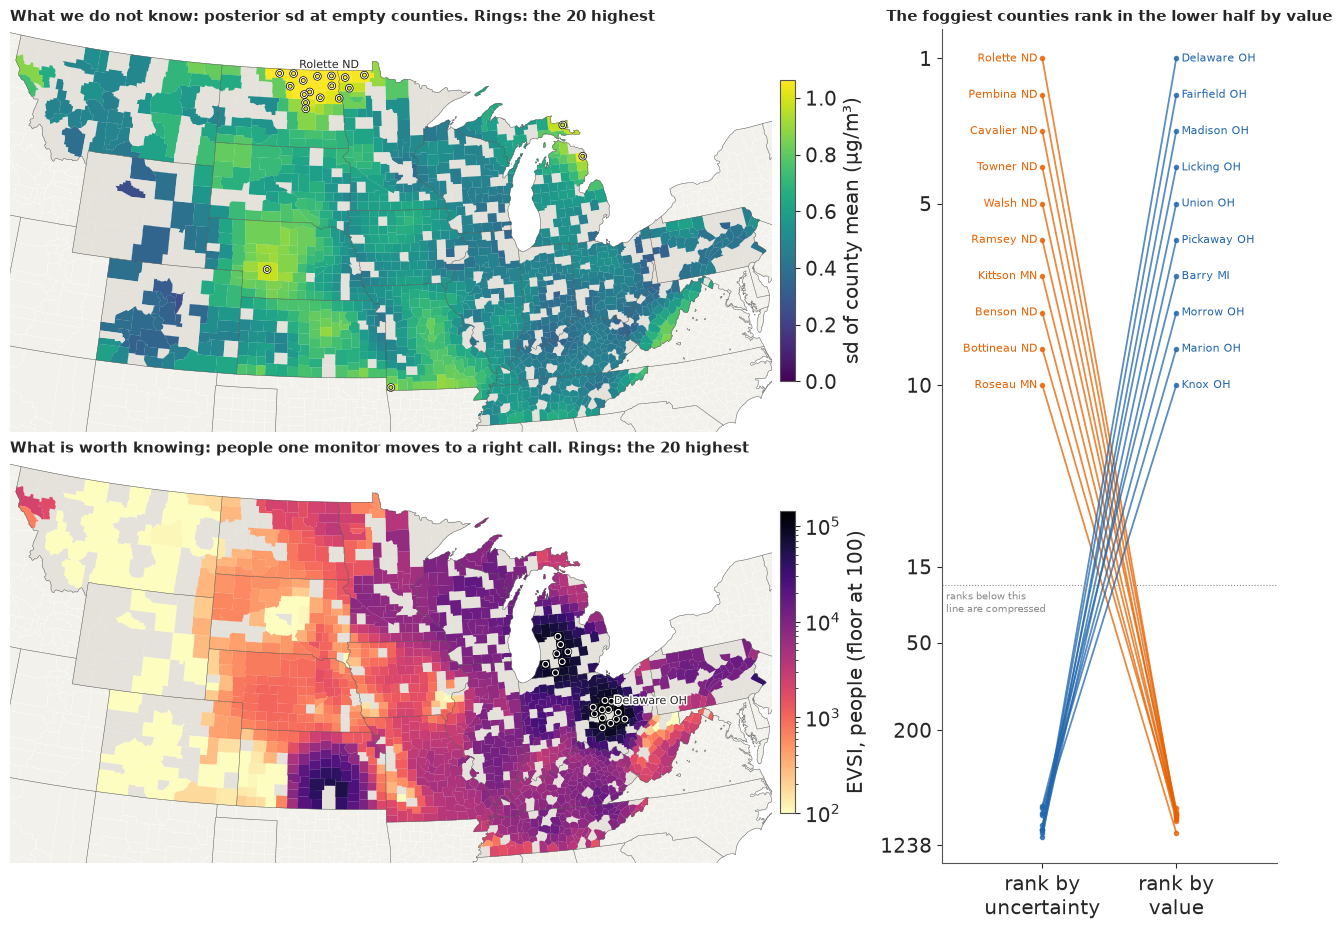

In [16]:
is_candidate = np.zeros(len(table), bool)
is_candidate[candidates] = True
rank_sd = pd.Series(-sd_ug[candidates], index=candidates).rank(method="first").astype(int)
rank_value = pd.Series(-first_value[candidates], index=candidates).rank(method="first").astype(int)
top_sd = rank_sd.sort_values().index[:20].to_numpy()
top_value = rank_value.sort_values().index[:20].to_numpy()
print(f"Top 20 by uncertainty and top 20 by single-monitor value share {len(set(top_sd) & set(top_value))} counties")
print(f"Best EVSI among the 20 most uncertain: {first_value[top_sd].max() / 1e3:.1f} thousand people "
      f"(best overall {first_value[ranked[0]] / 1e3:.0f})")
print(f"Median posterior sd: top 20 by uncertainty {np.median(sd_ug[top_sd]):.2f} {UG}, "
      f"top 20 by value {np.median(sd_ug[top_value]):.2f} {UG}")
print(f"Spearman rank correlation over {len(candidates):,} candidates: {rank_sd.corr(rank_value):.2f}")


def squash(rank):
    """Ranks 1-15 at full size, then a compressed tail down to the last candidate."""
    rank = np.asarray(rank, float)
    return np.where(rank <= 15, rank, 15 + 4 * np.log10(rank / 15))


fig = plt.figure(figsize=(13.5, 9.2), layout="constrained")
grid = fig.add_gridspec(2, 2, width_ratios=[2.5, 1])
ax_sd, ax_value, ax_bump = fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[1, 0]), fig.add_subplot(grid[:, 1])
shapes = paint(ax_sd, np.where(is_candidate, sd_ug, np.nan), "viridis", Normalize(0, np.quantile(sd_ug, 0.995)),
               labels=[(top_sd[0], short_name[top_sd[0]])])
halo = [pe.withStroke(linewidth=1.8, foreground="k")]
ax_sd.scatter(xy_county[top_sd, 0], xy_county[top_sd, 1], s=18, facecolor="none", edgecolor="w", lw=0.8, path_effects=halo)
ax_sd.set_title("What we do not know: posterior sd at empty counties. Rings: the 20 highest", loc="left", fontsize=11)
fig.colorbar(shapes, ax=ax_sd, shrink=0.75, label=f"sd of county mean ({UG})", pad=0.01)
shapes = paint(ax_value, np.where(is_candidate, np.maximum(first_value, 100), np.nan), "magma_r",
               LogNorm(100, np.nanmax(first_value)), labels=[(top_value[0], short_name[top_value[0]])])
ax_value.scatter(xy_county[top_value, 0], xy_county[top_value, 1], s=18, facecolor="none", edgecolor="w", lw=0.8,
                 path_effects=halo)
ax_value.set_title("What is worth knowing: people one monitor moves to a right call. Rings: the 20 highest", loc="left",
                   fontsize=11)
fig.colorbar(shapes, ax=ax_value, shrink=0.75, label="EVSI, people (floor at 100)", pad=0.01)

for ids, colour, align in ((top_sd[:10], PICK, "right"), (top_value[:10], BELOW, "left")):
    for i in ids:
        a, b = squash(rank_sd[i]), squash(rank_value[i])
        ax_bump.plot([0, 1], [a, b], color=colour, lw=1.3, alpha=0.75, marker="o", ms=3)
        x, y_ = (-0.04, a) if align == "right" else (1.04, b)
        ax_bump.text(x, y_, short_name[i], ha=align, va="center", fontsize=8, color=colour)
ticks = [1, 5, 10, 15, 50, 200, len(candidates)]
ax_bump.set_yticks(squash(ticks), [str(t) for t in ticks])
ax_bump.axhline(15.5, color=MUTED, lw=0.8, ls=":")
ax_bump.text(-0.72, 15.65, "ranks below this\nline are compressed", ha="left", va="top", fontsize=7.5, color=MUTED)
ax_bump.set_ylim(squash(len(candidates)) + 0.5, 0.2)
ax_bump.set_xlim(-0.75, 1.75)
ax_bump.set_xticks([0, 1], ["rank by\nuncertainty", "rank by\nvalue"])
ax_bump.grid(False)
foggy_ranks = rank_value[top_sd]
print(f"Value rank of the 20 foggiest: {foggy_ranks.min()}-{foggy_ranks.max()} of {len(candidates):,}, "
      f"median {foggy_ranks.median():.0f}")
ax_bump.set_title("The foggiest counties rank in the lower half by value", fontsize=11);

This is the lesson in one picture. The fog is over the northern Plains, and the value is in a few
pockets around Columbus, lower Michigan and Wichita. **The top 20 by uncertainty and the top 20 by
value have no county in common**, and over all candidates the two ranks are negatively correlated.
The most uncertain counties have about twice the posterior sd of the most valuable ones, and at best
a thirtieth of their value. By value they rank in the lower half of the candidates, not at the bottom:
the right panel compresses everything below rank 15.

Now you can say the sentence this notebook is meant to teach: *"Rolette County is very uncertain, and
it is not worth a monitor."* The reason is in the next figure.

Why is a foggy county worthless? For three counties below, the horizontal axis is what a new monitor
might read. The curve is how likely each reading is. The colour shows how many people's calls would
flip at that reading, and white means none. **Value needs the curve and the colour to overlap.**

     county  P(above)  chance a reading flips any call  max people flipped
Delaware OH      0.13                             0.74           2682750.0
 Rolette ND      0.20                             0.14            223773.0
    Lake IL      0.04                             0.45           8130150.0


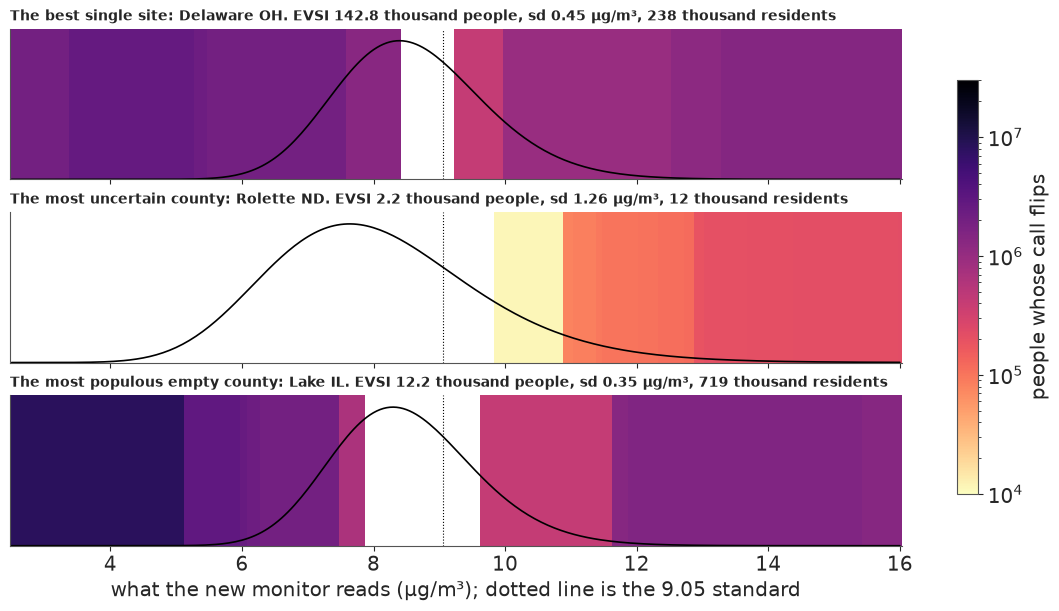

In [17]:
def reading_strip(network, c, grid_ug):
    """People whose call flips, and the predictive density of the reading, at each reading."""
    y = np.log(grid_ug)
    col = network.column(c)
    q = col[:, c] + network.noise
    mu_c = network.mu[:, c]
    local = np.flatnonzero((gap32[c] < network.radius) & network.open)
    p = probability_above(y, update_weights(y, mu_c, q), network.mu[:, local], network.var[:, local],
                          col[:, local], mu_c, q, network.line)
    flipped = ((p > 0.5) != (network.p[local] > 0.5)) * population[local]
    density = (np.exp(-0.5 * (y[:, None] - mu_c) ** 2 / q) / np.sqrt(2 * np.pi * q)).mean(axis=1) / grid_ug
    return flipped.sum(axis=1), density


foggy = int(top_sd[0])
biggest = int(candidates[np.argmax(population[candidates])])
trio = [("The best single site", int(ranked[0])), ("The most uncertain county", foggy),
        ("The most populous empty county", biggest)]
grid_ug = np.linspace(2.5, 16, 271)
fig, axes = plt.subplots(3, 1, figsize=(10.5, 6), sharex=True, layout="constrained")
rows = []
for ax, (title, c) in zip(axes, trio):
    people, density = reading_strip(net, c, grid_ug)
    shown = np.ma.masked_equal(people[None], 0)
    mesh = ax.pcolormesh(grid_ug, [0, 1], np.repeat(shown, 2, axis=0), cmap="magma_r", norm=LogNorm(1e4, 3e7),
                         shading="nearest", rasterized=True)
    ax.plot(grid_ug, 0.92 * density / density.max(), color="k", lw=1.2)
    ax.axvline(LINE, color="k", lw=0.8, ls=":")
    ax.set(yticks=[], ylim=(0, 1))
    ax.set_title(f"{title}: {short_name[c]}. EVSI {first_value[c] / 1e3:.1f} thousand people, "
                 f"sd {sd_ug[c]:.2f} {UG}, {population[c] / 1e3:.0f} thousand residents", loc="left", fontsize=10)
    rows.append({"county": short_name[c], "P(above)": p_now[c], "chance a reading flips any call":
                 float(np.trapezoid(density * (people > 0), grid_ug)), "max people flipped": people.max()})
axes[-1].set_xlabel(f"what the new monitor reads ({UG}); dotted line is the 9.05 standard")
fig.colorbar(mesh, ax=axes, shrink=0.8, label="people whose call flips")
print(pd.DataFrame(rows).round(2).to_string(index=False));

**Rolette ND:** the curve is wide, which is the fog, but nearly all of it sits over white. A call
flips only if the reading tops about 10, which has a 14% chance, and then few people are affected.
**Delaware OH:** the curve is narrower, yet it overlaps colour on both sides, and 74% of readings would
flip some call, up to 2.7 million people. **Lake IL** is the most populous empty county. A reading
could flip Chicago's calls, and 45% of readings flip something, but its EVSI is still only about 12
thousand. A flip is necessary and not sufficient: moving a county from 0.51 to 0.49 changes its label
and hardly changes its expected wrong calls.

## 6. Choosing twenty sites, and the second failure

One monitor is a formula. Twenty is a search: pick the best, update, repeat. Scoring every candidate
every round would take minutes. The **lazy loop** scores everyone once, then in later rounds rescores
only the 50 sites with the best last score. It rests on a site's gain rarely rising after another
pick. The pilot found that false as stated (gains rose in 75% of pairs) but harmless (median ratio
1.0002), and the lazy top 20 matched a full greedy run exactly at 100 and 200 draws. Because that
assumption is known to be false, the loop here pays for one full rescore on its last round.

In [18]:
def lazy_greedy(network, pool=candidates, rounds=20, top=50, recheck=False, start=None):
    """Pick `rounds` sites, rescoring only the best `top` by last score after the first round.

    `start` is a first round already scored, in the order of `pool`.
    """
    pool = np.asarray(pool)
    last = np.full(len(pool), np.inf) if start is None else np.array(start, float)
    free = np.ones(len(pool), bool)
    picks, gains, audit = [], [], None
    for round_ in range(rounds):
        todo = np.flatnonzero(free)
        lazy = todo[np.argsort(-last[todo])[: top]] if round_ > 0 else todo
        full_round = recheck and round_ == rounds - 1
        if round_ > 0 or start is None:
            last[todo if full_round else lazy] = network.score(pool[todo if full_round else lazy])
        best = lazy[np.argmax(last[lazy])]
        if full_round:
            everyone = pd.Series(last[todo], index=pool[todo]).rank(ascending=False)
            audit = {"lazy choice": short_name[pool[best]], "its rank in the full rescore": int(everyone[pool[best]]),
                     "full-rescore choice": short_name[pool[todo[np.argmax(last[todo])]]],
                     "candidates rescored": len(todo)}
        if last[best] <= 0:
            break
        picks.append(int(pool[best]))
        gains.append(float(last[best]))
        free[best] = False
        network.pick(int(pool[best]))
    return {"picks": picks, "gains": gains, "audit": audit, "network": network}


with stage("lazy greedy, 200 draws"):
    main = lazy_greedy(Network(field), recheck=True, start=first_value[candidates])
print("Final-round audit:", main["audit"])
print("Picks in order of the search, not of merit:")
print(", ".join(short_name[main["picks"]]))
print(f"Sum of greedy gains: {sum(main['gains']) / 1e6:.2f} million people")

Final-round audit: {'lazy choice': 'Greene OH', 'its rank in the full rescore': 1, 'full-rescore choice': 'Greene OH', 'candidates rescored': 1219}
Picks in order of the search, not of merit:
Delaware OH, Fairfield OH, Madison OH, Barry MI, Licking OH, Union OH, Pickaway OH, Ionia MI, Van Buren MI, Muskegon MI, Calhoun MI, Morrow OH, Montcalm MI, St. Joseph MI, Fayette OH, Champaign OH, Newaygo MI, Cass MI, Eaton MI, Greene OH
Sum of greedy gains: 1.72 million people


The audit passes: the last pick is still the best of all 1,219 remaining candidates. The audit reads
the last round only, so it says nothing about earlier rounds: for those we have only the pilot's
match above, on another fit. The 20 picks fall into two tight clusters, Ohio around Columbus and lower
Michigan. Do not read those clusters as a fact about the air yet: section 7 shows the search changes
which sites are picked. The search order is not a merit order, because each pick depends on the ones
before it. The first site is the only one scored exactly. Across fits and draw sets, Delaware County
OH came first in all but one pilot draw set.

Is that list a fact about the air, or about our draws? **Split the draws and run the search on each
part.** Our pilot asked for at least 16 of 20 in common. It started with 100 draws, so 50 a side, and
it failed at 12. Here is the same test on this fit, with four disjoint sets of 50, then two sets of
100.

In [19]:
def overlap(a, b):
    return len(set(a) & set(b))


with stage("split-half runs"):
    quarters = [lazy_greedy(Network(field, keep=slice(i, None, 4)))["picks"] for i in range(4)]
    halves = [lazy_greedy(Network(field, keep=slice(i, None, 2)))["picks"] for i in range(2)]
overlap_50 = [overlap(a, b) for i, a in enumerate(quarters) for b in quarters[i + 1:]]
overlap_100 = overlap(*halves)
print(f"Top-20 overlap, 50 draws against 50:   {overlap_50}")
print(f"Top-20 overlap, 100 draws against 100: {overlap_100}")

Top-20 overlap, 50 draws against 50:   [16, 16, 15, 17, 16, 19]
Top-20 overlap, 100 draws against 100: 17


**The second failure.** Read the printed pairs against the bar of 16. Some 50-draw pairs usually miss it, and across builds
they ranged from 13 to 19 with the 100-draw pairs often no better. The pilot's first split gave 12,
which is what sent us to 200 draws. Do not expect overlap to climb steadily with draws: the pilot's
overlaps were 12, 19 and then 17 at 50, 100 and 200 a side, and review reruns on fresh draw sets gave
16-18. **Read it as about 17 of 20, sometimes 13**, whatever the draws. That number alone rules out a
fixed ranked list, because the last places change with the random draws. All the picks stay nearby,
though: in the pilot, 90-100% of one half's picks had a pick of the other half within 100 km.

How far does a set of monitors reach? Below, the share of each county's uncertainty removed by the
picks so far. The readings are unknown, so this shows how much fog lifts, and not which way a county
moves. The picks crowd into the gaps around existing sites, and the effect fades within about 200 km.

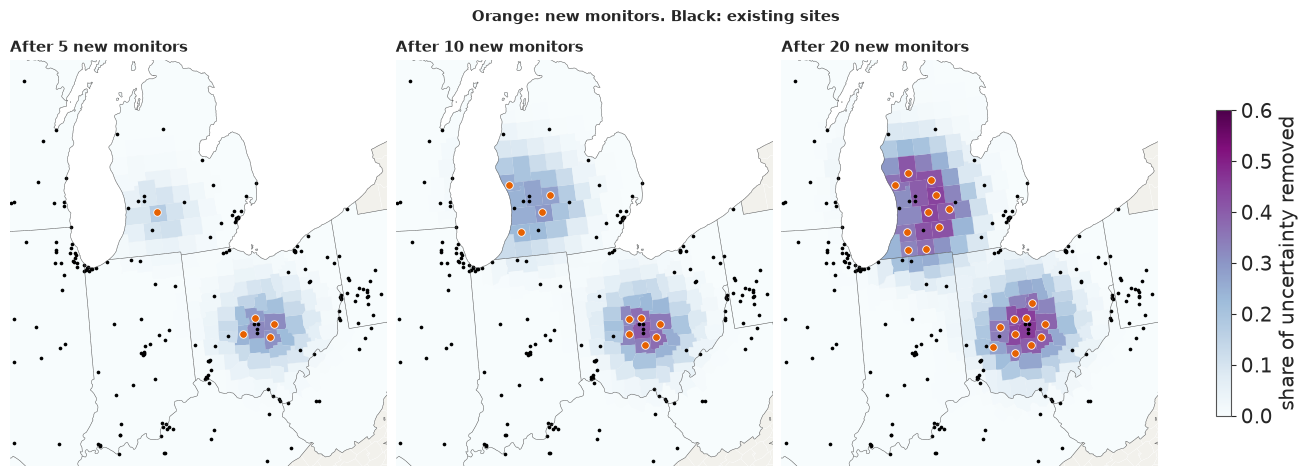

In [20]:
box = xy_county[main["picks"]]
window = dict(xlim=(box[:, 0].min() - 260, box[:, 0].max() + 260), ylim=(box[:, 1].min() - 260, box[:, 1].max() + 260))
fig, axes = plt.subplots(1, 3, figsize=(13, 4.8), layout="constrained")
for ax, k in zip(axes, (5, 10, 20)):
    after = variance - (main["network"].u[:, : k] ** 2).sum(axis=1)
    shapes = paint(ax, 1 - after.mean(axis=0) / variance.mean(axis=0), "BuPu", Normalize(0, 0.6))
    chosen = main["picks"][: k]
    ax.scatter(crop_sites["x_km"], crop_sites["y_km"], s=7, c="k", lw=0)
    ax.scatter(xy_county[chosen, 0], xy_county[chosen, 1], s=30, c=PICK, edgecolor="w", lw=0.6, zorder=3)
    ax.set(**window)
    ax.set_title(f"After {k} new monitors", loc="left", fontsize=11)
fig.colorbar(shapes, ax=axes, shrink=0.7, label="share of uncertainty removed")
fig.suptitle("Orange: new monitors. Black: existing sites", fontsize=11);

## 7. How many monitors? The third and fourth failures

A greedy gain is exact only in round one. After that, the loop keeps each draw's mean fixed, because
the first monitor's reading is unknown. So adding up the gains answers a slightly different question,
and the temptation to read that sum as "people moved" is strong. The honest number comes from
simulating readings **jointly** at all the chosen sites, updating every draw on all of them at once,
and making the calls. We simulate one set of 20 readings and use the first $k$ for each size, so the
sizes differ only by the sites added, and the step from one size to the next is measured directly.

    joint     se  in empty counties  sum of gains  overstated by
1   0.139  0.008             -0.003         0.143          1.025
2   0.202  0.010             -0.003         0.266          1.316
3   0.249  0.012             -0.001         0.381          1.530
5   0.372  0.018             -0.004         0.596          1.601
8   0.473  0.022              0.005         0.878          1.856
12  0.580  0.025              0.006         1.200          2.070
16  0.654  0.027              0.008         1.475          2.256
20  0.731  0.028              0.015         1.720          2.354
Worst overstatement here: 2.35x (2.1x across the pilot's draw sets)
                      overlap with EVSI top 20  value of 5 (M)  value of 20 (M)
Most uncertain                             0.0            0.04             0.09
Uncertainty x people                       3.0            0.07             0.54
Most populous empty                        3.0            0.11             0.56
EVSI, lazy greedy          

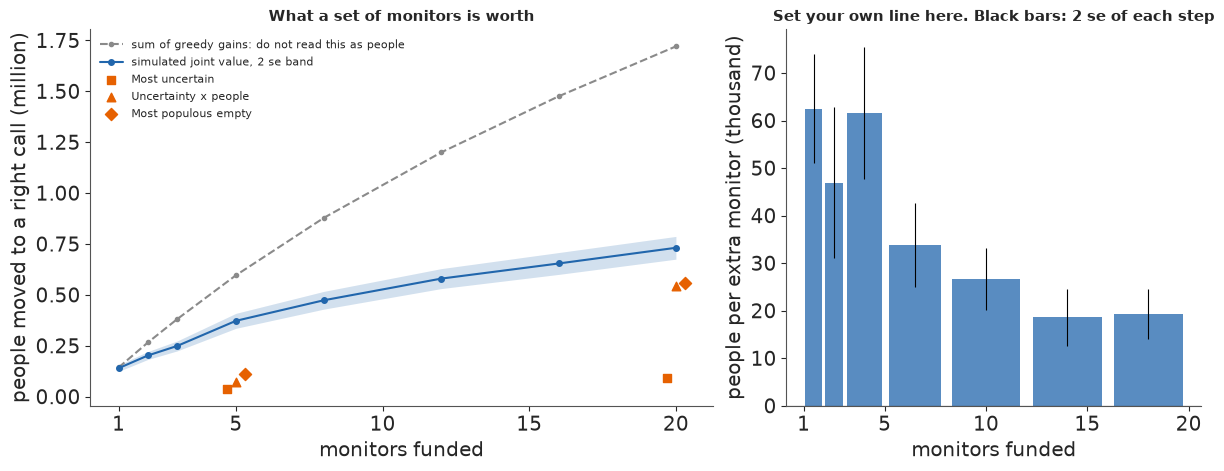

In [21]:
def joint_curve(field_, picks, sizes, sims=1500, seed=0, noise_scale=1.0):
    """Simulated gain of the first k picks, for each k in `sizes`: (sizes, sims) overall and in empty counties.

    The readings are nested. One set is drawn for the whole list, and a smaller set uses its first k. The
    lower Cholesky factor makes that exact, because its first k rows use only the first k normals.
    """
    check = np.random.default_rng(seed)
    picks = list(picks)[: max(sizes)]
    mu, noise = field_["means"].astype(float), field_["noise"] * noise_scale
    line, count = np.log(LINE), len(mu)
    rows_all = covariance_rows(field_, picks).astype(float)
    variance_ = (field_["eta2"][:, None] - (field_["half"] ** 2).sum(axis=1)).astype(float)
    lower = np.stack([linalg.cholesky(rows_all[i][:, picks] + noise[i] * np.eye(len(picks)), lower=True)
                      for i in range(count)])
    which = check.integers(count, size=sims)
    y = mu[which][:, picks] + np.einsum("sij,sj->si", lower[which], check.normal(size=(sims, len(picks))))
    p_before = ndtr((mu - line) / np.sqrt(variance_)).mean(axis=0)
    empty_people = population * ~monitored
    before = loss(p_before, population, "wrong"), loss(p_before, empty_people, "wrong")
    gains = np.empty((2, len(sizes), sims))
    for row, k in enumerate(sizes):
        root = lower[:, : k, : k]
        inverse = np.linalg.inv(root)
        half_log_det = np.log(np.diagonal(root, axis1=1, axis2=2)).sum(axis=1)
        solved = np.stack([linalg.cho_solve((root[i], True), rows_all[i, : k]) for i in range(count)])
        sd = np.sqrt(np.maximum(variance_ - (rows_all[:, : k] * solved).sum(axis=1), 1e-10))

        def after(s):
            gap = y[s, : k] - mu[:, picks[: k]]
            z = np.einsum("tij,tj->ti", inverse, gap)
            log = -0.5 * (z ** 2).sum(axis=1) - half_log_det
            w = np.exp(log - logsumexp(log))
            use = np.flatnonzero(w > 1e-6)
            p = w[use] @ ndtr((mu[use] + (gap[use][:, None] @ solved[use])[:, 0] - line) / sd[use])
            return loss(p, population, "wrong"), loss(p, empty_people, "wrong")

        with ThreadPoolExecutor(WORKERS) as pool:
            left = np.array(list(pool.map(after, range(sims))))
        gains[0, row], gains[1, row] = before[0] - left[:, 0], before[1] - left[:, 1]
    return gains[0], gains[1]


def joint_value(field_, picks, sims=800, seed=0, noise_scale=1.0):
    """What one set is worth: value and se, overall and in empty counties."""
    overall, in_empty = joint_curve(field_, picks, [len(picks)], sims, seed, noise_scale)
    root_n = np.sqrt(sims)
    return (float(overall.mean()), float(overall.std() / root_n), float(in_empty.mean()), float(in_empty.std() / root_n))


def rule_of_thumb(score, rounds=20):
    """Greedy on a simple score of the network, with no value of information."""
    network, picks = Network(field), []
    for _ in range(rounds):
        values = score(network).copy()
        values[picks] = -np.inf
        best = candidates[np.argmax(values[candidates])]
        picks.append(int(best))
        network.pick(int(best))
    return picks


def fog(network):
    """Posterior sd in µg/m³, the measure ranked in section 5, after the picks so far."""
    return np.exp(network.mu.mean(axis=0)) * np.sqrt(network.var.mean(axis=0) + network.mu.var(axis=0))


with stage("rules of thumb"):
    rules = {"Most uncertain": rule_of_thumb(fog),
             "Uncertainty x people": rule_of_thumb(lambda n: fog(n) * population),
             "Most populous empty": candidates[np.argsort(-population[candidates])][:20].tolist()}

with stage("joint value"):
    sizes = (1, 2, 3, 5, 8, 12, 16, 20)
    overall, in_empty = joint_curve(field, main["picks"], sizes)
    joint = pd.DataFrame({"joint": overall.mean(axis=1), "se": overall.std(axis=1) / np.sqrt(overall.shape[1]),
                          "in empty counties": in_empty.mean(axis=1)}, index=sizes)
    joint["sum of gains"] = np.cumsum(main["gains"])[np.array(sizes) - 1]
    joint["overstated by"] = joint["sum of gains"] / joint["joint"]
    per_rule = {name: [joint_value(field, picks[: k]) for k in (5, 20)] for name, picks in rules.items()}
    halves_value = [joint_value(field, picks) for picks in halves]
    between_windows = joint_value(field, main["picks"], noise_scale=1.2)
print((joint / [1e6, 1e6, 1e6, 1e6, 1]).round(3).to_string())
print(f"Worst overstatement here: {joint['overstated by'].max():.2f}x (2.1x across the pilot's draw sets)")
compare = pd.DataFrame({name: {"overlap with EVSI top 20": overlap(picks, main["picks"]),
                               "value of 5 (M)": values[0][0] / 1e6, "value of 20 (M)": values[1][0] / 1e6}
                        for (name, picks), values in zip(rules.items(), per_rule.values())}).T
compare.loc["EVSI, lazy greedy"] = [20, joint.loc[5, "joint"] / 1e6, joint.loc[20, "joint"] / 1e6]
print(compare.round(2).to_string())
print(f"Joint value of each half's 20 picks: {halves_value[0][0] / 1e6:.2f} and {halves_value[1][0] / 1e6:.2f} million "
      f"(se {halves_value[0][1] / 1e6:.2f})")
print(f"Reading noise variance 20% larger, for the gap between the window read and the window scored: "
      f"{between_windows[0] / 1e6:.2f} million (se {between_windows[1] / 1e6:.2f})")
print(f"Of the 20 picks' {joint.loc[20, 'joint'] / 1e6:.2f} million, {joint.loc[20, 'in empty counties'] / 1e6:.2f} million "
      f"falls in empty counties (se {in_empty[-1].std() / np.sqrt(in_empty.shape[1]) / 1e6:.2f}); "
      f"wrong-call people there now: {risk[~monitored].sum() / 1e6:.2f} million")
steps = pd.DataFrame({"from": sizes[:-1], "to": sizes[1:]})
per_step = np.diff(overall, axis=0) / np.diff(sizes)[:, None] / 1e3
steps["people per extra monitor (thousand)"] = per_step.mean(axis=1)
steps["se"] = per_step.std(axis=1) / np.sqrt(per_step.shape[1])
print(steps.round(1).to_string(index=False))
print(f"Monitors 12 to 20 add {(overall[-1] - overall[list(sizes).index(12)]).mean() / 1e6:.3f} million "
      f"(se {(overall[-1] - overall[list(sizes).index(12)]).std() / np.sqrt(overall.shape[1]) / 1e6:.3f}); the first five "
      f"do {joint.loc[5, 'joint'] / joint.loc[20, 'joint']:.0%} of the work of twenty")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), width_ratios=[1.5, 1], layout="constrained")
ax = axes[0]
ax.plot(sizes, joint["sum of gains"] / 1e6, color=MUTED, ls="--", marker="o", ms=3,
        label="sum of greedy gains: do not read this as people")
ax.fill_between(sizes, (joint["joint"] - 2 * joint["se"]) / 1e6, (joint["joint"] + 2 * joint["se"]) / 1e6,
                color=BELOW, alpha=0.2, lw=0)
ax.plot(sizes, joint["joint"] / 1e6, color=BELOW, marker="o", ms=4, label="simulated joint value, 2 se band")
for (name, values), marker, nudge in zip(per_rule.items(), "s^D", (-0.3, 0, 0.3)):
    ax.scatter([5 + nudge, 20 + nudge], [v[0] / 1e6 for v in values], marker=marker, s=38, c=PICK, label=name, zorder=3)
ax.set_xticks([1, 5, 10, 15, 20])
ax.set(xlabel="monitors funded", ylabel="people moved to a right call (million)")
ax.set_title("What a set of monitors is worth", fontsize=11)
ax.legend(fontsize=8, loc="upper left")
ax = axes[1]
middle = (steps["from"] + steps["to"]) / 2
ax.bar(middle, steps["people per extra monitor (thousand)"], width=np.diff(sizes) * 0.85, color=BELOW, alpha=0.75,
       yerr=2 * steps["se"], ecolor="k", error_kw={"lw": 0.8})
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks([1, 5, 10, 15, 20])
ax.set(xlabel="monitors funded", ylabel="people per extra monitor (thousand)")
ax.set_title("Set your own line here. Black bars: 2 se of each step", fontsize=11);

**The third failure.** The dashed line is what you get by adding up greedy gains: about 1.7 million
people at 20 monitors. The simulation says about 0.73. **The sum overstates by more than 2x here**,
by 1.7-2.4x at twenty across builds, and by 1.3-2.1x in the pilot, whose joint values were 1.08-1.22
million. The sums are also unstable across draw sets (1.52-2.47 million in the pilot). Only the first monitor is safe, since
its gain is an exact value. This list is worth **about 0.7-1.0 million people for 20 monitors**:
about 0.7-0.95 on these draws and 0.9-1.0 on a disjoint set, as section 8 prints. The pilot's
1.08-1.22 is higher, and we did not explain that gap.

**The stopping rule** is the right-hand panel: how many people the next monitors move, per monitor. We
have no sourced cost for a monitor, so we will not draw the line for the planner. Draw yours in
people per monitor, and stop where the bars cross it. The bars fall from about 60 thousand for the
first few monitors to about 30 by 8-12 and about 20 by 12-20. Monitors 12 to 20 still add about 0.15
million people, many standard errors from zero. It steps down after five and flattens by 12-20, but it
stays well above zero, so your line sets the stopping point. The first five monitors do about half
the work of twenty. These bars are for the first list: the moving-means list below has only two
points printed.

**Against the rules of thumb,** at five monitors EVSI is worth about three to five times either
sensible rule, and many times the "most uncertain" rule. At twenty the sensible rules catch up to
about three quarters of this list, because any list that crowds into populous near-line areas finds
some value. The pure uncertainty rule never does.

**The window gap.** The value is a what-if, as the top of this notebook said. As a rough size, year effects
here have an sd of about 0.1, so a three-year mean drifts by about 0.05 on the log scale. That raises
the variance of the reading noise by about a fifth, or its sd by about a tenth, and the printed run
with that noise loses under a tenth of the value.

### The fourth failure: the search's shortcut bends the picks

The third failure looks like a reporting error, and it is more than that. After a pick, a county's
variance shrinks but its mean stays put, since the reading is unknown. So a county near 0.5 stays near
0.5 and keeps drawing picks, when half the possible readings would in truth have settled it. So the
first search misjudges what a set is worth. The fix is to score what a set leaves behind. Readings move a county's
mean by a normal amount, with a variance that adds up pick by pick, and the expected loss is then an
integral per county. The new search below uses that score, and `joint_curve` then values its list
exactly as it valued the first.

In [22]:
class JointNetwork(Network):
    """A search that scores what a set leaves behind, with each county's mean free to move.

    For one Gaussian county, readings at a set of sites move its mean by a normal amount, with a
    variance that adds up pick by pick, and the expected loss is then a one-dimensional integral that
    adds across counties. Draws are pooled into one mean and variance per county, and covariances come
    from every fifth draw. This is a score for the search and not a value: `joint_curve` measures sets.
    """

    def __init__(self, field_, every=5, **options):
        super().__init__(field_, keep=slice(None, None, every), **options)
        means = field_["means"][:, self.where]
        variance_ = field_["eta2"][:, None] - (field_["half"][:, :, self.where] ** 2).sum(axis=1)
        self.m = means.mean(axis=0) - self.line
        self.total = variance_.mean(axis=0) + means.var(axis=0)
        self.moved = np.zeros_like(self.total)
        self.z = np.float32(ndtri((np.arange(32) + 0.5) / 32))[:, None]

    def left(self, slots, moved):
        moved = np.minimum(moved, 0.9999 * self.total[slots])
        p = ndtr((self.m[slots] + self.z * np.sqrt(moved)) / np.sqrt(self.total[slots] - moved))
        return loss(p, self.weight[self.where[slots]], self.objective).mean()

    def shift(self, c, slots):
        """How much a reading at `c` adds to the variance of each county's mean."""
        cross = self.block[:, CANDIDATE_ROW[c]][:, slots]
        if self.k:
            cross = cross - (self.u[:, : self.k, c][:, None] @ self.u[:, : self.k][:, :, self.where[slots]])[:, 0]
        return (cross ** 2 / (self.var[:, c] + self.noise)[:, None]).mean(axis=0)

    def reach_of(self, c):
        return np.flatnonzero(gap32[c, self.where] < self.radius)

    def value(self, c):
        slots = self.reach_of(c)
        if slots.size == 0:
            return 0.0
        return float(self.left(slots, self.moved[slots]) - self.left(slots, self.moved[slots] + self.shift(c, slots)))

    def pick(self, c):
        slots = self.reach_of(c)
        self.moved[slots] += self.shift(c, slots)
        super().pick(c)


def nearest_gap(picks):
    """Median km from each pick to the nearest other pick."""
    gaps = gap_county[np.ix_(picks, picks)] + np.diag(np.full(len(picks), np.inf))
    return float(np.median(gaps.min(axis=1)))


with stage("search with moving means"):
    spread = lazy_greedy(JointNetwork(field), top=len(candidates))["picks"]
with stage("joint value"):
    spread_overall, spread_in_empty = joint_curve(field, spread, (5, 20))
print("The moving-means list:", ", ".join(short_name[spread]))
print(f"Shares {overlap(spread, main['picks'])} of 20 with the fixed-means list; states "
      f"{pd.Series(table['state'].to_numpy()[spread]).value_counts().to_dict()}; median km to the nearest other pick "
      f"{nearest_gap(spread):.0f}, against {nearest_gap(main['picks']):.0f}")
root_n = np.sqrt(overall.shape[1])
for row, k in enumerate((5, 20)):
    fixed_list = overall[sizes.index(k)]
    gap_ = spread_overall[row].mean() - fixed_list.mean()
    gap_se = np.sqrt(spread_overall[row].var() + fixed_list.var()) / root_n
    print(f"Joint value of {k:2d}: fixed means {fixed_list.mean() / 1e6:.2f}, moving means "
          f"{spread_overall[row].mean() / 1e6:.2f} million (difference {gap_ / 1e6:.2f}, se {gap_se / 1e6:.2f})")
print(f"Of the moving-means list's {spread_overall[1].mean() / 1e6:.2f} million, {spread_in_empty[1].mean() / 1e6:.2f} "
      f"million falls in empty counties (se {spread_in_empty[1].std() / root_n / 1e6:.2f})")

The moving-means list: Delaware OH, Barry MI, Madison OH, Harvey KS, Cass MI, Fairfield OH, Wood OH, Ionia MI, Greene OH, Licking OH, Muskegon MI, Butler KS, St. Joseph MI, Union OH, Boone IN, Livingston MI, Lapeer MI, Shiawassee MI, Pickaway OH, Van Buren MI
Shares 13 of 20 with the fixed-means list; states {'Michigan': 9, 'Ohio': 8, 'Kansas': 2, 'Indiana': 1}; median km to the nearest other pick 43, against 40
Joint value of  5: fixed means 0.37, moving means 0.42 million (difference 0.04, se 0.03)
Joint value of 20: fixed means 0.73, moving means 0.91 million (difference 0.18, se 0.04)
Of the moving-means list's 0.91 million, 0.03 million falls in empty counties (se 0.01)


**The moving-means list is worth a fifth to a quarter more** at 20 monitors, and it shares only about 13
picks with the first. It keeps most of Columbus and lower Michigan and adds Kansas and Indiana. The
gain at five monitors is small. Its score is a crude approximation, so treat this list as a lower
bound on what a better search could find, and not as a best list. Section 8 scores both lists on the
three other fields, and the moving-means list wins on each. The clusters themselves survive: median
spacing is about 43 km against 40, and 17 of 20 picks stay in Ohio and Michigan. From here on, "the
first list" is the fixed-means one and "the moving-means list" is the other.

**Now the catch from section 4, in numbers.** Of the first list's value, only about 0.01-0.05 million
falls in empty counties, where about 1.15 million people are at risk. The moving-means list is no
different, at about 0.03 million. The rest is a firmer read on places that already have monitors.

## 8. Whose objective, which standard, which sites?

**Objective is a choice.** A state may not want to find exceedances, so "fewest wrong calls" is not
automatically its goal. We keep the p = 0.5 calling rule and change what counts as a loss: missed
exceedances only, false exceedances only, or wrong counties with every county counting once. Then we
repeat the search at the old 12.0 standard, which is thin: few counties are anywhere near it.

At 12.05: 1 undecided counties (Lincoln MT), 0.00 million people at risk of a wrong call; 1 picks before value ran out
People                   shares 20 with People; states {'Ohio': 10, 'Michigan': 10}
Missed exceedances       shares  0 with People; states {'Kansas': 10, 'Missouri': 7, 'Indiana': 1}
False exceedances        shares 12 with People; states {'Ohio': 15, 'Michigan': 5}
Counties, unweighted     shares 11 with People; states {'Michigan': 11, 'Indiana': 4, 'Ohio': 3}
People in empty counties shares  1 with People; states {'Indiana': 11, 'Michigan': 4, 'North Dakota': 1}
People, 12.0 standard    shares  0 with People; states {'Montana': 1}
Counties with P(above) of 0.4-0.6: Franklin OH 0.52, Kent MI 0.51, Montgomery OH 0.44, Sedgwick KS 0.43, Lake IN 0.41, Lucas OH 0.48, Hamilton IN 0.55, St. Joseph IN 0.54, Kalamazoo MI 0.55, Elkhart IN 0.47, Hendricks IN 0.42


20 picks made for empty counties: 0.06 million people moved there (se 0.02), 0.42 million overall


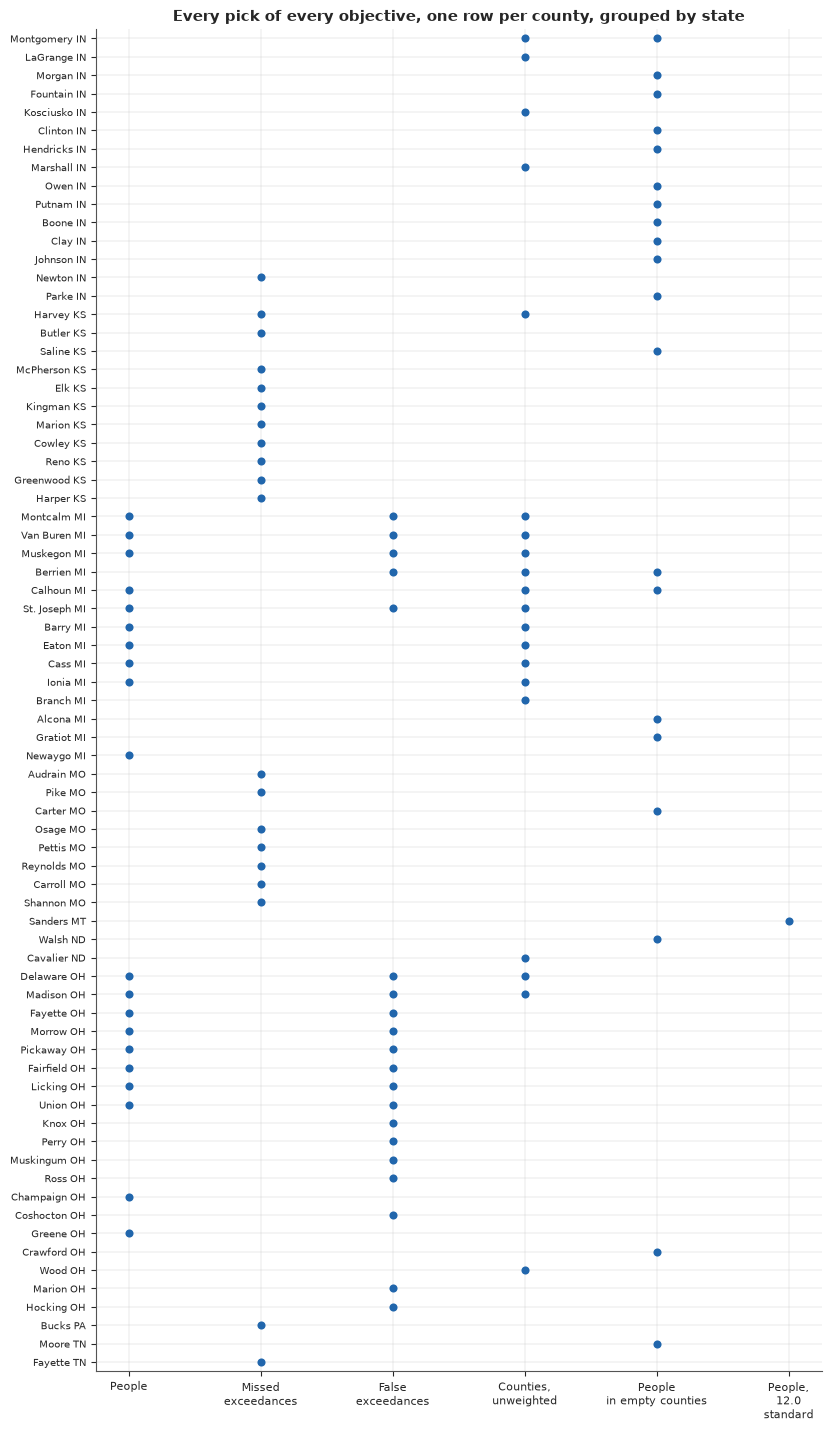

In [23]:
with stage("objectives"):
    runs = {"People": main["picks"],
            "Missed exceedances": lazy_greedy(Network(field, objective="missed"))["picks"],
            "False exceedances": lazy_greedy(Network(field, objective="false"))["picks"],
            "Counties, unweighted": lazy_greedy(Network(field, weight=np.ones(len(table))))["picks"],
            "People in empty counties": lazy_greedy(Network(field, weight=population * ~monitored))["picks"],
            "People, 12.0 standard": lazy_greedy(Network(field, line=12.05))["picks"]}
twelve = Network(field, line=12.05)
print(f"At 12.05: {twelve.open.sum()} undecided counties ({', '.join(short_name[twelve.open])}), "
      f"{loss(twelve.p, twelve.weight, 'wrong') / 1e6:.2f} million "
      f"people at risk of a wrong call; {len(runs['People, 12.0 standard'])} picks before value ran out")
for name, picks in runs.items():
    print(f"{name:24s} shares {overlap(picks, main['picks']):2d} with People; states "
          f"{pd.Series(table['state'].to_numpy()[picks]).value_counts().head(3).to_dict()}")

close = np.flatnonzero((p_now > 0.4) & (p_now < 0.6))
print("Counties with P(above) of 0.4-0.6:",
      ", ".join(f"{short_name[i]} {p_now[i]:.2f}" for i in close[np.argsort(-population[close])]))
empty_value = joint_value(field, runs["People in empty counties"])
print(f"20 picks made for empty counties: {empty_value[2] / 1e6:.2f} million people moved there "
      f"(se {empty_value[3] / 1e6:.2f}), {empty_value[0] / 1e6:.2f} million overall")

labels = list(runs)
every = sorted({c for picks in runs.values() for c in picks},
               key=lambda c: (table["state"].iloc[c], -sum(c in p for p in runs.values())))
fig, ax = plt.subplots(figsize=(8.2, 0.17 * len(every) + 1.8), layout="constrained")
for x, name in enumerate(labels):
    for y_, c in enumerate(every):
        if c in runs[name]:
            ax.scatter(x, y_, s=34, c=BELOW, lw=0)
ax.set_xticks(range(len(labels)), [t.replace(", ", ",\n").replace(" ", "\n", 1) for t in labels], fontsize=8)
ax.set_yticks(range(len(every)), short_name[every], fontsize=7.5)
ax.set(ylim=(len(every) - 0.5, -0.5))
ax.set_title("Every pick of every objective, one row per county, grouped by state", fontsize=11)
ax.grid(True, lw=0.3);

The list depends heavily on the objective, about as much as it does on the method term in section 8.

- **False exceedances** keeps 12 of the 20, and stays in Ohio and Michigan.
- **Unweighted counties** keeps 11, moving out of Ohio towards Michigan and Indiana.
- **Missed exceedances** keeps almost none. It leaves for wherever a county sits just below 0.5, and
  which counties those are changes with the fit: Kansas and Missouri here, Indiana, Michigan and
  Illinois in another build. With the calling rule fixed, this objective pays for pushing a
  below-the-line county over 0.5, and Sedgwick KS, near 0.43, is the kind of county it hunts.
- **People in empty counties** keeps one. This is the objective closest to the brief's wording, and
  about half of it moves to the counties around Indianapolis. The prize is small: those 20 picks move about 0.06
  million people in empty counties (se 0.02), of 1.15 million at risk.
- **The 12.0 standard** has almost nothing to decide in this crop: at most one undecided county and
  one pick, in Montana, and none in some builds. We do not force a shortlist out of that.

### A second draw set, and the excluded sites

Two more runs, each searched both ways. One uses a disjoint set of 200 draws from the same fit, which
measures draw noise at the size we actually use. The other drops the excluded sites and refits. These
sites have no row in EPA's workbook and carry an exclusion covering the annual standard. They read
air, so they stay in by default, but they may be source sites.

In [24]:
main_field_rows = {"fixed-means list": (joint.loc[20, "joint"], joint.loc[20, "se"]),
                   "moving-means list": (spread_overall[1].mean(), spread_overall[1].std() / root_n)}
main_field_rows |= {"fixed, searched here": main_field_rows["fixed-means list"],
                    "moving, searched here": main_field_rows["moving-means list"]}
worth = {"these 200 draws": main_field_rows}
del net, twelve, field
main.pop("network")
gc.collect()


def on_field(other):
    """Search both ways on another field, then value the main lists and its own lists there."""
    fixed = lazy_greedy(Network(other))["picks"]
    moving = lazy_greedy(JointNetwork(other), top=len(candidates))["picks"]
    named = {"fixed-means list": main["picks"], "moving-means list": spread,
             "fixed, searched here": fixed, "moving, searched here": moving}
    return fixed, moving, {name: joint_value(other, picks, seed=1)[:2] for name, picks in named.items()}


with stage("second draw set"):
    field_two = make_field(d, fit, shift=5)
    second, spread_second, worth["a disjoint 200 draws"] = on_field(field_two)
    del field_two
    gc.collect()
print(f"Top 20, two disjoint sets of 200 draws: {overlap(main['picks'], second)} in common; "
      f"moving-means search: {overlap(spread, spread_second)}")

excluded = set(checks["excluded_sites"])
kept = crop_sites[~crop_sites["site"].isin(excluded)].reset_index(drop=True)
print(f"{len(excluded)} excluded sites in the contiguous US, {len(crop_sites) - len(kept)} in the crop: "
      f"refit on {len(kept)} sites")
d_drop = design(kept)
with stage("refit without excluded sites"):
    idata_drop = fit_m1(d_drop, RANDOM_SEED + 1)
summary_drop = az.summary(idata_drop, var_names=list(NAMES), ci_prob=0.9, ci_kind="eti", round_to=3)
print(summary_drop.loc[["eta", "ell"]].to_string())
print(f"max r_hat {summary_drop['r_hat'].astype(float).max():.3f}; "
      f"divergences {int(idata_drop.sample_stats['diverging'].sum())}")
fit_drop = draws_of(idata_drop)
del idata_drop
gc.collect()
with stage("county conditionals, greedy without excluded sites"):
    field_drop = make_field(d_drop, fit_drop)
    p_drop = Network(field_drop).p.copy()
    dropped, spread_dropped, worth["no excluded sites"] = on_field(field_drop)
    del field_drop
    gc.collect()
gap_lists = gap_county[np.ix_(dropped, main["picks"])]
print(f"Top 20 with and without them: {overlap(main['picks'], dropped)} in common; "
      f"{(gap_lists.min(axis=1) < 100).mean():.0%} of the new picks lie within 100 km of a kept pick; "
      f"moving-means search: {overlap(spread, spread_dropped)} in common")
print("States, fixed means:", pd.Series(table["state"].to_numpy()[dropped]).value_counts().to_dict())
print("States, moving means:", pd.Series(table["state"].to_numpy()[spread_dropped]).value_counts().to_dict())
print(f"Mean |change in P(above)| {np.abs(p_now - p_drop).mean():.3f}; 99th percentile "
      f"{np.quantile(np.abs(p_now - p_drop), 0.99):.3f}; counties changing side of 0.5: "
      f"{((p_now > 0.5) != (p_drop > 0.5)).sum()}")
print("Change side:", ", ".join(f"{short_name[i]} {p_now[i]:.2f} to {p_drop[i]:.2f}"
                                for i in np.flatnonzero((p_now > 0.5) != (p_drop > 0.5))))

Top 20, two disjoint sets of 200 draws: 18 in common; moving-means search: 19
30 excluded sites in the contiguous US, 15 in the crop: refit on 404 sites


        mean      sd  eti90_lb  eti90_ub  ess_bulk  ess_tail  r_hat  mcse_mean  mcse_sd
eta    0.222   0.041     0.168     0.296  1717.799  1380.310  0.999      0.001    0.001
ell  350.169  83.959   241.285   500.012  1383.455  1246.699  0.999      2.366    2.737
max r_hat 1.005; divergences 0


Top 20 with and without them: 11 in common; 85% of the new picks lie within 100 km of a kept pick; moving-means search: 12 in common
States, fixed means: {'Michigan': 16, 'Illinois': 2, 'Wisconsin': 1, 'Ohio': 1}
States, moving means: {'Michigan': 8, 'Ohio': 8, 'Illinois': 4}
Mean |change in P(above)| 0.010; 99th percentile 0.141; counties changing side of 0.5: 6
Change side: Kalamazoo MI 0.55 to 0.48, St. Joseph IN 0.54 to 0.38, Hamilton IN 0.55 to 0.36, Franklin OH 0.52 to 0.37, Kent MI 0.51 to 0.48, Lincoln MT 0.68 to 0.43


Two disjoint sets of 200 draws share about 18 of 20 picks, which is draw noise at the size we use.
Dropping the 15 excluded sites in the crop keeps the fit healthy, moves `ell` from about 310 to about
350 km, and shares only about 11 of 20 picks (9-12 in the pilot). That is **more than draw noise**,
and it is not a local change for the first list: most of its Ohio picks go, and Michigan and Illinois
take over, so "within 100 km of a kept pick" flatters it, because one kept pick at Delaware OH sits
near the whole Ohio ring. The moving-means list holds up better and keeps its Ohio picks. About 6
counties change side of 0.5, printed above, Franklin among them. One of its four sites, reading
9.86, is excluded; we did not isolate which sites drive the move. The choice needs someone who knows why each was
excluded.

### The method term, against the instruments themselves

Section 2 flagged this. The model learns the method term across sites, and BAM sites are rural, so
the term can pick up rural air. There is a direct check: an FRM filter and a continuous instrument
running at one site on one day saw the same air.

In [25]:
print(f"BAM sites: mean {crop_sites.loc[crop_sites['share_BAM'] > 0.5, 'mean'].mean():.1f} {UG}, mean log density "
      f"{crop_sites.loc[crop_sites['share_BAM'] > 0.5, 'log_density'].mean():.1f}; all other sites "
      f"{crop_sites.loc[crop_sites['share_BAM'] <= 0.5, 'mean'].mean():.1f} {UG}, "
      f"{crop_sites.loc[crop_sites['share_BAM'] <= 0.5, 'log_density'].mean():.1f}")
pairs_table = pd.DataFrame(checks["paired_method"]).T[["sites", "site_days", "mean", "se"]]
pairs_table["model"] = summary.loc[[f"beta_method[{m}]" for m in pairs_table.index], "mean"].astype(float).to_numpy()
print(pairs_table.round(3).to_string())

prior_mean = pairs_table.loc[list(METHODS), "mean"].to_numpy(float)
prior_sd = np.maximum(pairs_table.loc[list(METHODS), "se"].to_numpy(float), 0.01)
with stage("refit with paired method prior"):
    idata_pair = fit_m1(d, RANDOM_SEED + 2, method_prior=(prior_mean, prior_sd))
summary_pair = az.summary(idata_pair, var_names=list(NAMES), ci_prob=0.9, ci_kind="eti", round_to=3)
print(summary_pair.filter(like="beta_method", axis=0)[["mean", "sd"]].to_string())
print(f"max r_hat {summary_pair['r_hat'].astype(float).max():.3f}; "
      f"min bulk ESS {summary_pair['ess_bulk'].astype(float).min():.0f}; "
      f"divergences {int(idata_pair.sample_stats['diverging'].sum())}")
fit_pair = draws_of(idata_pair)
del idata_pair
gc.collect()
with stage("county conditionals, greedy with paired prior"):
    field_pair = make_field(d, fit_pair)
    p_pair = Network(field_pair).p.copy()
    risk_pair = population * np.minimum(p_pair, 1 - p_pair)
    paired_list, spread_paired, worth["paired method prior"] = on_field(field_pair)
    del field_pair
    gc.collect()
print(f"With the paired prior: {risk_pair.sum() / 1e6:.2f} million at risk (was {risk.sum() / 1e6:.2f}), "
      f"{risk_pair[~monitored].sum() / 1e6:.2f} in empty counties (was {risk[~monitored].sum() / 1e6:.2f}); "
      f"{((p_pair > 0.01) & (p_pair < 0.99)).sum()} undecided (was {undecided.sum()}); "
      f"{(p_pair > 0.5).sum()} called above, {population[p_pair > 0.5].sum() / 1e6:.1f} million people "
      f"(was {(p_now > 0.5).sum()}, {population[p_now > 0.5].sum() / 1e6:.1f})")
moved_side = np.flatnonzero((p_now > 0.5) != (p_pair > 0.5))
print("Change side:", ", ".join(f"{short_name[i]} {p_now[i]:.2f} to {p_pair[i]:.2f}" for i in moved_side))
print(f"Top 20 against the main list: fixed means {overlap(main['picks'], paired_list)} of 20, "
      f"moving means {overlap(spread, spread_paired)} of 20")
print("States, fixed means:", pd.Series(table["state"].to_numpy()[paired_list]).value_counts().to_dict())
print("States, moving means:", pd.Series(table["state"].to_numpy()[spread_paired]).value_counts().to_dict())
print(pd.DataFrame({field_name: {list_name: f"{value / 1e6:.2f} ({se / 1e6:.2f})" for list_name, (value, se) in row.items()}
                    for field_name, row in worth.items()}).T.to_string())

BAM sites: mean 6.2 µg/m³, mean log density 3.1; all other sites 8.0 µg/m³, 4.8
       sites  site_days   mean     se  model
T640   114.0    34684.0  0.063  0.007  0.033
BAM     20.0     4767.0 -0.035  0.017 -0.111
other    8.0     1689.0  0.027  0.040  0.007


                     mean     sd
beta_method[T640]   0.063  0.010
beta_method[BAM]   -0.051  0.014
beta_method[other]  0.034  0.029
max r_hat 1.007; min bulk ESS 1377; divergences 0


With the paired prior: 7.36 million at risk (was 10.43), 0.44 in empty counties (was 1.15); 259 undecided (was 452); 2 called above, 1.0 million people (was 9, 10.9)
Change side: Kalamazoo MI 0.55 to 0.37, St. Joseph IN 0.54 to 0.31, Hamilton IN 0.55 to 0.26, Franklin OH 0.52 to 0.35, Kent MI 0.51 to 0.32, Wayne MI 0.70 to 0.44, Cook IL 0.74 to 0.50
Top 20 against the main list: fixed means 0 of 20, moving means 12 of 20
States, fixed means: {'Illinois': 5, 'Michigan': 4, 'Missouri': 3, 'Iowa': 3, 'Nebraska': 2, 'Wisconsin': 1, 'Indiana': 1, 'Kansas': 1}
States, moving means: {'Michigan': 8, 'Ohio': 7, 'Illinois': 4, 'Wisconsin': 1}
                     fixed-means list moving-means list fixed, searched here moving, searched here
these 200 draws           0.73 (0.03)       0.91 (0.03)          0.73 (0.03)           0.91 (0.03)
a disjoint 200 draws      0.97 (0.05)       1.20 (0.05)          0.99 (0.05)           1.17 (0.05)
no excluded sites         0.73 (0.04)       0.90 (0.04)       

**The pairs and the model disagree, and that moves the totals and the values more than anything else
in this section.** BAM sites are cleaner and more rural than the rest, and the across-site term puts
BAM about 10% low where the pairs say about 3%. T640 goes the other way, and T640 sites are the most common. With a prior
from the pairs and nothing else changed, the fit stays clean, and:

- about 7.4 million people are at risk, not 10, and about 0.4 million in empty counties, not 1.15;
- about 250 counties are undecided, not 450;
- only 2-3 counties are called above. Cook IL lands on the line at about 0.5, so the people in
  counties called above swing between about 1 and 6 million on that one call. Franklin OH, Wayne MI
  and Kent MI all cross below;
- the two main lists move about 0.3-0.4 million people on this field, not 0.7-1.2, and the moving-means
  list still wins. A moving-means list searched on this field is worth about 0.5-0.6 million, so
  0.3-0.4 is a floor;
- the first search's own list barely resembles its main list (0-7 of 20 across fits), while the
  moving-means search keeps about 12 of 20.

The last table reads as value in millions, with the se in brackets. Its first two columns keep the
same two lists and change the field they are scored on, so the differences between rows are as much a
statement about the draws and the model as about the lists. Its last two columns value the lists
searched on that field, which is a different test. There the moving-means search wins on the second
draw set and with the paired prior, and the two are about level without the excluded sites. The
paired gap is less firm than it looks: a stored fit from another build, valued the same way, had the
two searches level at about 0.5.

We keep the learned term in the main run and report this beside it, because the pairs are not the
last word. They are selected sites, they exist only on FRM sampling days, and this is one refit. But
the reader should not take 10 million as settled.

## 9. The band, and what to tell the planner

Four lists, all from the moving-means search, since its main list scored higher on all four fields
and it keeps more of its picks when the field changes.
Two are draw sets of the main fit, so draw noise counts once. The other two change an assumption:
without the excluded sites, and with a method prior from the pairs. A county's standing is how
many of the four picked it. We sort the table by place, not by rank, because the data do not support
a rank. The first search's lists are printed by state as well, because they show the instability the
band is there to catch.

32 counties on at least one list; 15 on at least 3 of 4; 9 on all 4
       county    state  lists  people  P(above)  km to nearest monitor
     Barry MI Michigan      4   64000      0.17                     40
      Cass MI Michigan      4   52000      0.14                     26
     Ionia MI Michigan      3   66000      0.12                     47
    Lapeer MI Michigan      3   89000      0.02                     34
Livingston MI Michigan      3  197000      0.15                     43
  Muskegon MI Michigan      3  177000      0.09                     49
St. Joseph MI Michigan      3   61000      0.19                     44
 Van Buren MI Michigan      3   76000      0.18                     38
  Delaware OH     Ohio      4  238000      0.13                     12
 Fairfield OH     Ohio      4  168000      0.03                     31
   Licking OH     Ohio      4  185000      0.03                     37
   Madison OH     Ohio      4   46000      0.01                     31
  Pickawa

Six random sets of 20 from the band: 0.81-0.88 million (moving-means list 0.91, fixed-means list 0.73)


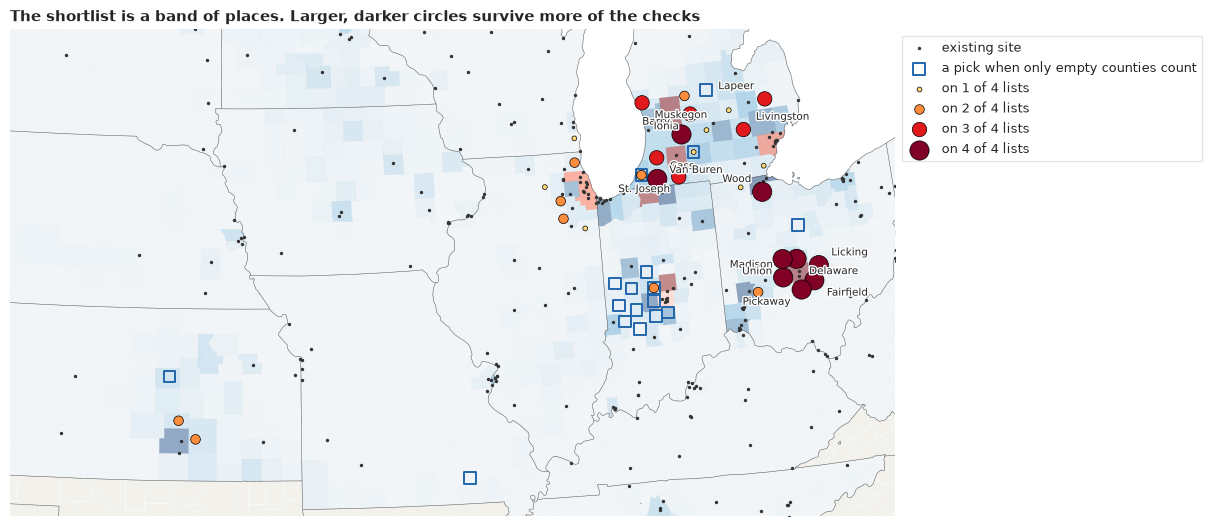

In [26]:
lists = {"these draws": spread, "other draws": spread_second, "no excluded sites": spread_dropped,
         "paired method prior": spread_paired}
ASSUMPTIONS = len(lists)
count = pd.Series([c for picks in lists.values() for c in picks]).value_counts()
band = pd.DataFrame({"county": short_name[count.index], "state": table["state"].to_numpy()[count.index],
                     "lists": count.to_numpy(), "people": population[count.index].round(-3).astype(int),
                     "P(above)": p_now[count.index].round(2),
                     "km to nearest monitor": distance(xy_county[count.index], d["xy"]).min(axis=1).round(0).astype(int)},
                    index=count.index)
core = band[band["lists"] >= 3]
print(f"{len(band)} counties on at least one list; {len(core)} on at least 3 of {ASSUMPTIONS}; "
      f"{(band['lists'] == ASSUMPTIONS).sum()} on all {ASSUMPTIONS}")
print(core.sort_values(["state", "county"]).to_string(index=False))
print(band.groupby("state")["lists"].agg(["size", "sum"]).sort_values("sum", ascending=False).to_string())
print("Fixed-means lists, for comparison:")
for name, picks in {"these draws": main["picks"], "other draws": second, "half A": halves[0], "half B": halves[1],
                    "no excluded sites": dropped, "paired method prior": paired_list}.items():
    print(f"  {name:20s}{pd.Series(table['state'].to_numpy()[picks]).value_counts().head(4).to_dict()}")

with stage("random sets from the band"):
    field = make_field(d, fit)
    picker = np.random.default_rng(RANDOM_SEED)
    samples = [joint_value(field, picker.choice(band.index.to_numpy(), 20, replace=False).tolist(), sims=400)[0]
               for _ in range(6)]
    del field
    gc.collect()
print(f"Six random sets of 20 from the band: {min(samples) / 1e6:.2f}-{max(samples) / 1e6:.2f} million "
      f"(moving-means list {spread_overall[1].mean() / 1e6:.2f}, fixed-means list {joint.loc[20, 'joint'] / 1e6:.2f})")

for_empty = runs["People in empty counties"]
places = xy_county[band.index[band["lists"] >= 2]]
fig, ax = plt.subplots(figsize=(12, 7.2), layout="constrained")
shapes = paint(ax, p_now, CLOSE_CALL, Normalize(0, 1))
shapes.set_alpha(0.5)
ax.scatter(crop_sites["x_km"], crop_sites["y_km"], s=6, c="#333333", lw=0, label="existing site")
ax.scatter(xy_county[for_empty, 0], xy_county[for_empty, 1], s=70, marker="s", facecolor="none", edgecolor=BELOW, lw=1.4,
           label="a pick when only empty counties count")
ax.scatter(xy_county[band.index, 0], xy_county[band.index, 1], s=band["lists"] ** 2 * 12, c=band["lists"], cmap="YlOrRd",
           norm=Normalize(0, ASSUMPTIONS), edgecolor="k", lw=0.5, zorder=3)
for size in range(1, ASSUMPTIONS + 1):
    ax.scatter([], [], s=size ** 2 * 12, color=plt.get_cmap("YlOrRd")(size / ASSUMPTIONS), edgecolor="k", lw=0.5,
               label=f"on {size} of {ASSUMPTIONS} lists")
labelled = band.index[band["lists"] >= 3]
for turn, i in enumerate(labelled[np.argsort(xy_county[labelled, 1])]):
    dx, dy = ((-9, -9), (9, -9), (-9, 9), (9, 9))[turn % 4]
    ax.annotate(short_name[i].rsplit(" ", 1)[0], xy_county[i], xytext=(dx, dy), textcoords="offset points", fontsize=7.5,
                ha="right" if dx < 0 else "left", va="center",
                path_effects=[pe.withStroke(linewidth=2, foreground="w")], zorder=4)
ax.set(xlim=(places[:, 0].min() - 330, places[:, 0].max() + 150), ylim=(places[:, 1].min() - 150, places[:, 1].max() + 130))
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=True, fontsize=9)
ax.set_title("The shortlist is a band of places. Larger, darker circles survive more of the checks",
             loc="left", fontsize=11);

The band has about 30 counties. **About 15 are on at least three of the four lists, and about 9 are on
all four.** Those 9 are the robust core, mostly around Columbus with a few in lower Michigan. The rest
depend on an assumption someone has to own, and the Ohio picks depend on the search: on the first
search, dropping the excluded sites takes Ohio from half the list to a single pick.

Random sets of 20 from the band are worth about the same as each other, a little below the
moving-means list and above the first list. So a planner choosing any 20 from around these places is
close to the best this analysis found, which is a rough statement and not a guarantee: six random
sets at 400 simulations each is a small test. The table above is sorted by place on purpose. The blue squares
are the picks when only empty counties count, and the map makes plain that they are a different
answer.

### What this run cost, and what it never touched

In [27]:
price = pd.Series(PRICE, name="seconds").round(0).astype(int)
print(price.to_string())
print(f"Total in stages: {price.sum() / 60:.1f} min on {CORES} cores")
maps = Path("/proc/self/maps").read_text() if Path("/proc/self/maps").exists() else ""
assert not any(name.startswith(("jax.", "jaxlib")) for name in sys.modules), "the annual path executed JAX"
assert "libcuda" not in maps, "CUDA is mapped into the annual path"
print("No JAX module executed, no CUDA library mapped.")

prior check                                             2
fit M1                                                146
checks                                                  1
county conditionals                                     3
first round, every candidate                            9
brute-force check                                      10
lazy greedy, 200 draws                                 21
split-half runs                                        37
rules of thumb                                          1
joint value                                           143
search with moving means                                9
objectives                                             76
second draw set                                        68
refit without excluded sites                          131
county conditionals, greedy without excluded sites     58
refit with paired method prior                        140
county conditionals, greedy with paired prior          56
random sets fr

Measured peak memory and wall time are in the banner at the top. The largest single items are the
three fits and the joint simulations. JAX never ran, so no GPU extra is needed.

### What to tell the planner

1. **Do not fund "where we are most uncertain".** The map of uncertainty and the map of value are
   different maps here, and the most uncertain counties are close to worthless for this decision.
2. **Decide what the monitors are for.** If the aim is a firmer read on exposure across the
   populated Midwest, the band around Columbus and lower Michigan is the answer, at about 0.9-1.2
   million people moved for twenty monitors from the better list. If the aim is to resolve calls in
   empty counties, the list changes, about half of it moving to the counties around Indianapolis, and
   the gain is far smaller.
3. **Settle the method term first.** It costs nothing in monitors, and it changes the number at risk
   by about 3 million and takes the main lists' value from 0.7-1.2 to 0.3-0.4 million. A moving-means
   list rebuilt for the pairs is worth about 0.5-0.6 million. Same-site, same-day
   instrument pairs are selected sites on FRM sampling days, so they are evidence, not the last word.
4. **Buy in stages, from the band, and stop on your own line.** The first five monitors do about half
   the work of twenty. After that each monitor adds less, and it still adds something at twenty.
   Rescore each stage with the joint simulation.
5. **Check before signing.** Satellite-derived PM2.5, EPA's fused surfaces and low-cost sensor
   networks were not used here, and we did not check what they show. This field probably overstates
   the fog in empty counties without them. Start with the counties in the band and with Sedgwick
   County's neighbours, then check the far-from-monitors bias from section 3.

No new monitor can help the February 2027 designations. These sites inform the next cycle, from
2028-2030 data at the earliest.

### What this notebook cannot claim

- **Anything national, coastal, Californian or Southeastern.** No national model has been fitted.
- **A fixed ranked list.** Overlap is about 17 of 20 across draws, about 11 of 20 if the excluded
  sites go, and 0-7 of 20 on the first search (about 12 on the moving-means search) if the method
  term changes.
- **A best list.** The moving-means search beat the first on the main fit, on a crude score, and the
  two came out about level without the excluded sites when that field was searched afresh. A better
  one may exist.
- **That 10 million is the true number at risk.** It depends on the method term and on what counts
  as truth in a county: 1.4-23 million across the cases in section 4.
- **Greedy gains as people moved,** or a stopping budget in monitors. The rule is built, and the
  planner's line is not ours to draw.
- **Validated wrong-call rates.** Only a few far-away new sites sit near the line.
- **That preferential siting is or is not resolved.** The far new sites lean low, and M2 was not sampled.
- **That the daily model is unnecessary.** Neither it nor its gate was run.
- **Anything about a wrong call in law.** The loss is on exposure at a county's population centre, and
  a large county is one point here.
- **A speed for your laptop.** Every time here is from one Ryzen 5950X, on two cores.

**The bigger lesson is the plain question.** Before funding a measurement, ask what you would do
differently if you had it. If the answer is "nothing", it does not matter how little you know.

## Try it yourself

Each of these ran after the finished notebook on 2 cores, in under a minute. First rebuild the field,
which the notebook freed: `field = make_field(d, fit)`. Assign each result as written. A bare
`lazy_greedy(...)` line leaves the whole network in IPython's output history, and `del field` then
frees nothing.

1. **A cheaper instrument.** A low-cost sensor reads with more noise. Run
   `cheap = lazy_greedy(Network(field, noise_scale=4.0))["picks"]`, and compare with
   `overlap(cheap, main["picks"])` and `joint_value(field, cheap, noise_scale=4.0)[0]`. Pass the same
   `noise_scale` to both, or the value is for a better sensor than the one you chose for. How much
   of the list survives?
2. **A logistics rule.** Suppose a monitor needs a county of at least 50,000 people. Restrict the pool
   with `limited = lazy_greedy(Network(field), pool=candidates[population[candidates] >= 50_000])["picks"]`.
   Which picks fall out, and what does it cost in joint value?
3. **A shorter reach.** Run `del field` and `gc.collect()` first: a second field is large. Hold `ell`
   at its 10th percentile with `short = {**fit, "ell": np.full_like(fit["ell"], np.quantile(fit["ell"], 0.1))}`,
   then run `reach = lazy_greedy(Network(make_field(d, short, count=100)))["picks"]`. If a monitor sees
   less far, do the clusters spread out?